# Notebook for Explainable AI for Transformer Architectures

### Imports & loading data

In [1]:
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification
import torch
import matplotlib.pyplot as plt
import numpy as np

import os
from transformers import pipeline 

from transformers import pipeline
import seaborn as sns


2025-10-29 22:21:48.459496: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-10-29 22:21:48.477349: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8473] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-10-29 22:21:48.482863: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1471] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-10-29 22:21:48.498598: I tensorflow/core/platform/cpu_feature_guard.cc:211] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Load model, tokenizer and lebel encoding

# Path to your fine-tuned checkpoint
ckpt_dir = "roberta_large_weighted_results/checkpoint-2616" 
base_model_name = "roberta-large"

# --- Load label encoding EXACTLY as in training ---
label_list = ['anger', 'disgust', 'fear', 'happiness', 'neutral', 'sadness', 'surprise']  # adjust if needed
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for i, label in enumerate(label_list)}

# --- Load model with correct architecture ---
config = AutoConfig.from_pretrained(base_model_name)
config.id2label = id2label
config.label2id = label2id

tokenizer = AutoTokenizer.from_pretrained(base_model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    ckpt_dir,
    config=config  # ensures correct hidden size (1024 for large)
)

print("Loaded fine-tuned RoBERTa-large model with correct label mapping")
print("Label mapping:", id2label)


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta_large_weighted_results/checkpoint-2616 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded fine-tuned RoBERTa-large model with correct label mapping
Label mapping: {0: 'anger', 1: 'disgust', 2: 'fear', 3: 'happiness', 4: 'neutral', 5: 'sadness', 6: 'surprise'}


## Gradient x Input

In [3]:
def gradient_x_input(model, inputs):
    inputs_embeds = model.get_input_embeddings()(inputs.input_ids)
    inputs_embeds = inputs_embeds.clone().detach().requires_grad_(True)
    outputs = model(inputs_embeds=inputs_embeds, attention_mask=inputs.attention_mask)
    outputs.logits[:, outputs.logits.argmax()].backward()
    # Fix for NoneType issue — return zero tensor if grad is None
    if inputs_embeds.grad is None:
        raise RuntimeError("Gradients are not computed! Make sure inputs_embeds is correctly passed through the model.")

    return inputs_embeds.grad * inputs_embeds




## Conservative Propagation

In [4]:
# Attention Layer - Conservative Propagation
def modified_attention_forward(attention_layer, hidden_states, relevance_scores):
    attention_scores = (hidden_states @ hidden_states.transpose(-1, -2)) / hidden_states.size(-1)**0.5
    attention_probs = attention_scores.softmax(dim=-1).detach()
    context_layer = attention_probs @ hidden_states
    propagated_relevance = (attention_probs.transpose(-1, -2) @ relevance_scores)
    return context_layer, propagated_relevance

# LayerNorm Layer - Conservative Propagation
def modified_layernorm_forward(layernorm_layer, hidden_states, relevance_scores):
    mean = hidden_states.mean(-1, keepdim=True)
    variance = hidden_states.var(-1, keepdim=True, unbiased=False)
    normed = (hidden_states - mean) / (variance + layernorm_layer.eps).sqrt()
    propagated_relevance = relevance_scores / (variance + layernorm_layer.eps).sqrt()
    return normed.detach(), propagated_relevance

### Pertubating

In [5]:
def perturb_input_and_evaluate(model, tokenizer, text, relevance_scores, perturb_type='remove'):
    tokens = tokenizer.tokenize(text)
    
    if perturb_type == 'remove':
        sorted_indices = torch.argsort(relevance_scores[0].norm(dim=-1), descending=False)
    else:
        sorted_indices = torch.argsort(relevance_scores[0].norm(dim=-1), descending=True)

    sorted_indices = sorted_indices.tolist()

    perturbed_texts = []
    for i in range(1, len(tokens) + 1):
        perturbed_tokens = tokens[:]
        for idx in sorted_indices[:i]:
            if idx < len(perturbed_tokens):
                perturbed_tokens[idx] = '[PAD]'
        perturbed_texts.append(tokenizer.convert_tokens_to_string(perturbed_tokens))

    confidences = []
    for pert_text in perturbed_texts:
        pert_inputs = tokenizer(pert_text, return_tensors='pt')
        pert_output = model(**pert_inputs)
        confidences.append(pert_output.logits.softmax(dim=-1).max().item())

    return confidences

## Visualisation of analysis

In [6]:
# TODO: These are interesting visuals for your presentation. Why did you choose these sentences? Did you expect these outcomes? What does this tell you? 

sentences = [
    "Think he needs me to work with him, but he still actually wants everything his way. I mean, that's laughable",
    "Jericho you rolled your eyes to that. No, not really",
    "It's making me feel sick.",
    "Doing what he wants and manipulating people and I haven't stood for it for a moment",
    "Tara, you're clearly in the middle of this.",
    "He told Jerry that I was against him trying to get him out.",
    "Don't get angry at me.",
    "Have you gone and told anyone else?",
    "Peter not daring to look over.",
    "But with that necklace I know that I'm safe",
    "The fact that I'm completely safe tonight means if it's a tie Tara Pete and Jericho are gonna have to draw for rocks",
    "So there's a chance that you could go home tonight",
    "I don't even feel bad.",
    "With Luke gone, I moved one rung higher.",
    "You know and I don't want to let the emotions get involved and he won't either",
    "I think I definitely am a big target to go home now because it's just easy Jericho.",
    "I guess Jerry's hurting.",
    "but Lachie won the immunity necklace.",
    "It was Tara who spilled the beans to me.",
    "And so the other three will then draw rocks",
    "Come tribal council, it was between physical threat Ziggy and loose cannon Luke."
]
for text in sentences:
    inputs = tokenizer(text, return_tensors="pt")
    outputs = model(**inputs)
    predicted_class = outputs.logits.argmax(dim=-1).item()
    pred_label = model.config.id2label[predicted_class]
    print(f"Sentence: {text} \n predicted emotion: {pred_label}\n")

Sentence: Think he needs me to work with him, but he still actually wants everything his way. I mean, that's laughable 
 predicted emotion: anger

Sentence: Jericho you rolled your eyes to that. No, not really 
 predicted emotion: anger

Sentence: It's making me feel sick. 
 predicted emotion: anger

Sentence: Doing what he wants and manipulating people and I haven't stood for it for a moment 
 predicted emotion: surprise

Sentence: Tara, you're clearly in the middle of this. 
 predicted emotion: anger

Sentence: He told Jerry that I was against him trying to get him out. 
 predicted emotion: surprise

Sentence: Don't get angry at me. 
 predicted emotion: surprise

Sentence: Have you gone and told anyone else? 
 predicted emotion: sadness

Sentence: Peter not daring to look over. 
 predicted emotion: surprise

Sentence: But with that necklace I know that I'm safe 
 predicted emotion: anger

Sentence: The fact that I'm completely safe tonight means if it's a tie Tara Pete and Jericho ar

Gradient × Input visualization


>>> TEXT: Think he needs me to work with him, but he still actually wants everything his way. I mean, that's laughable


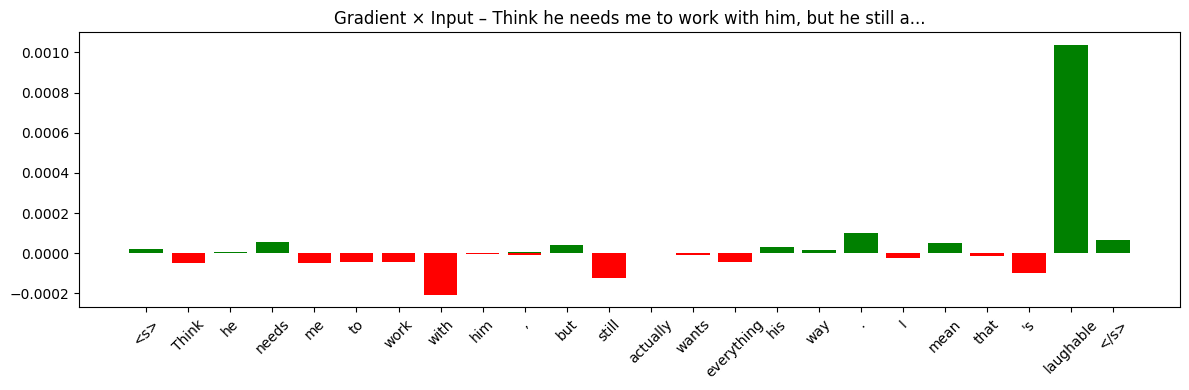


>>> TEXT: Jericho you rolled your eyes to that. No, not really


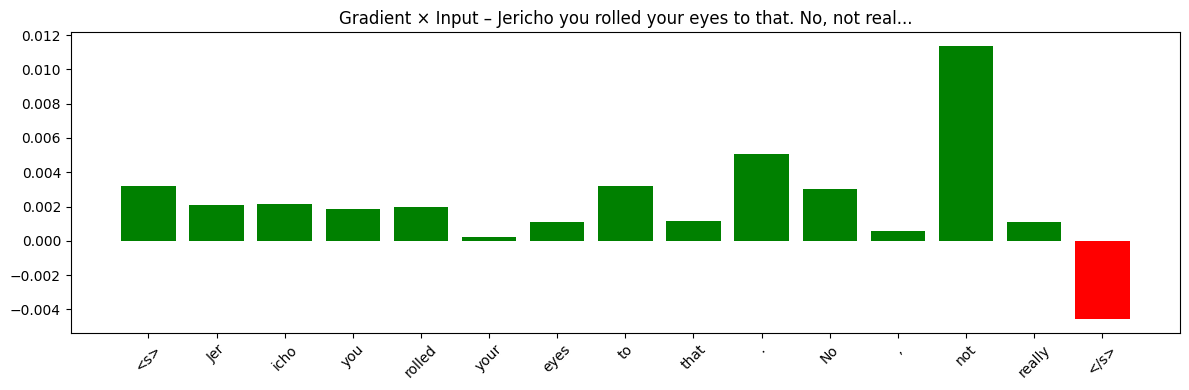


>>> TEXT: It's making me feel sick.


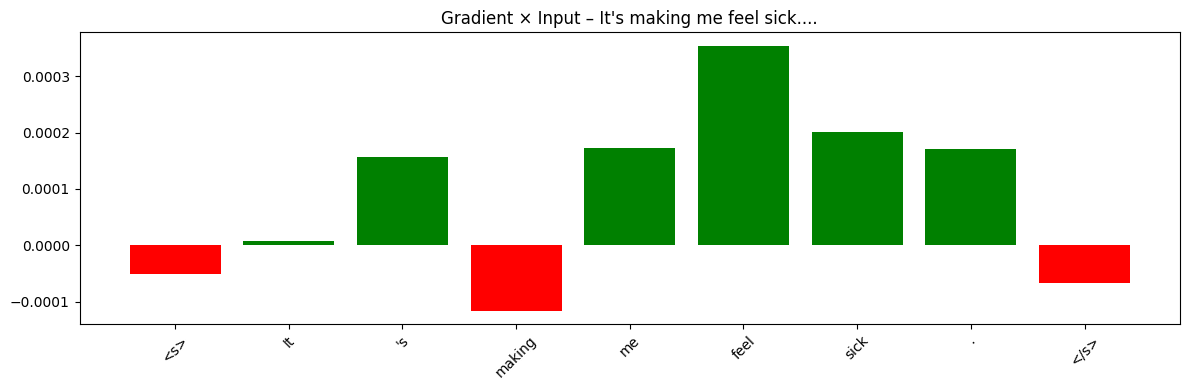


>>> TEXT: Doing what he wants and manipulating people and I haven't stood for it for a moment


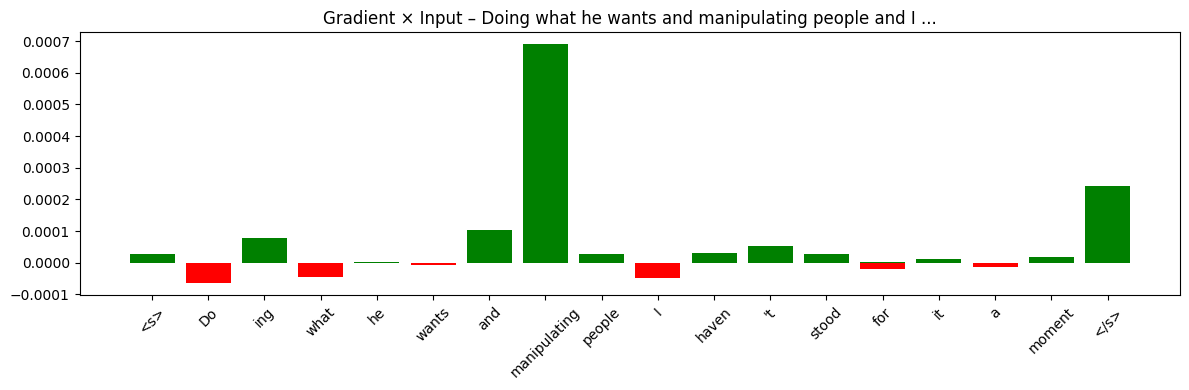


>>> TEXT: Tara, you're clearly in the middle of this.


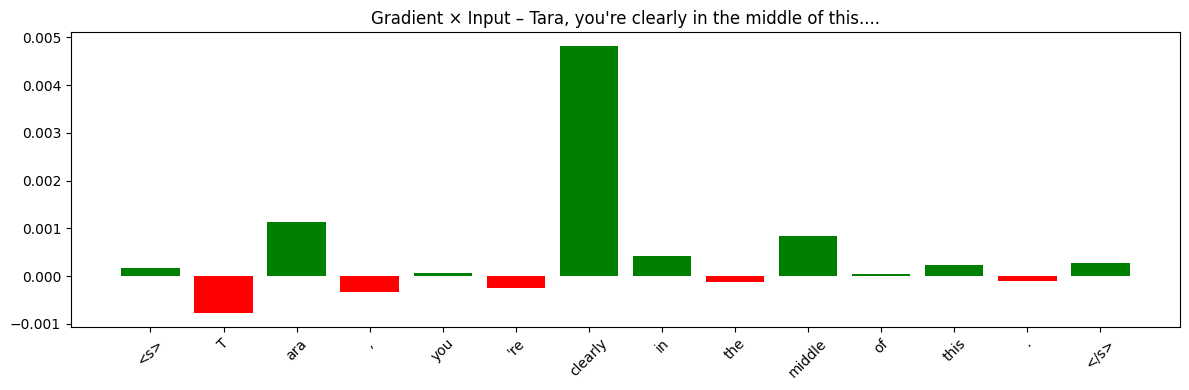


>>> TEXT: He told Jerry that I was against him trying to get him out.


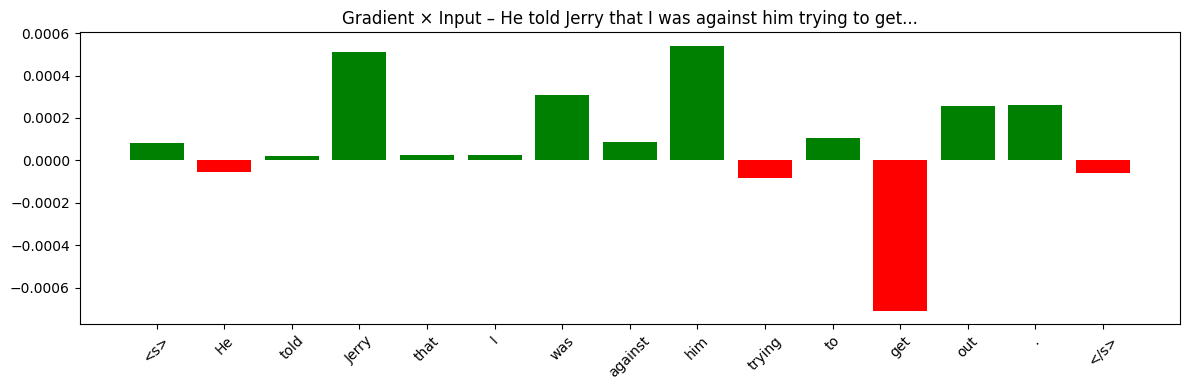


>>> TEXT: Don't get angry at me.


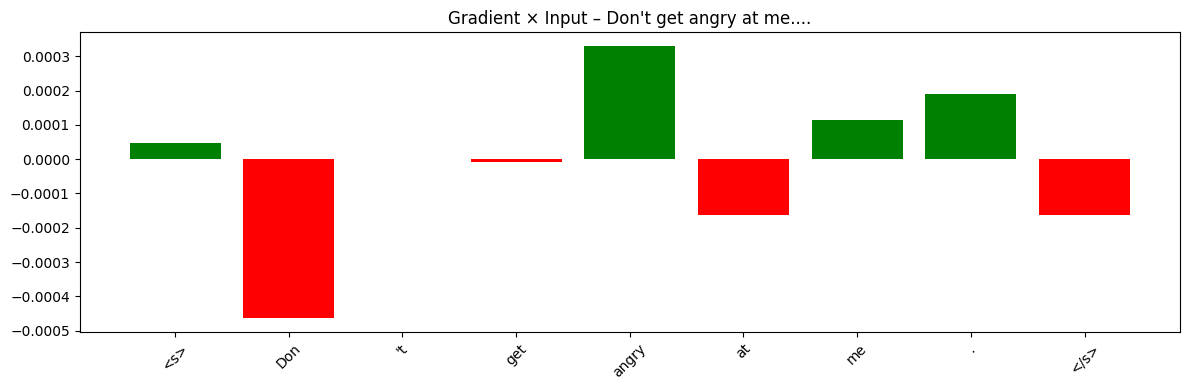


>>> TEXT: Have you gone and told anyone else?


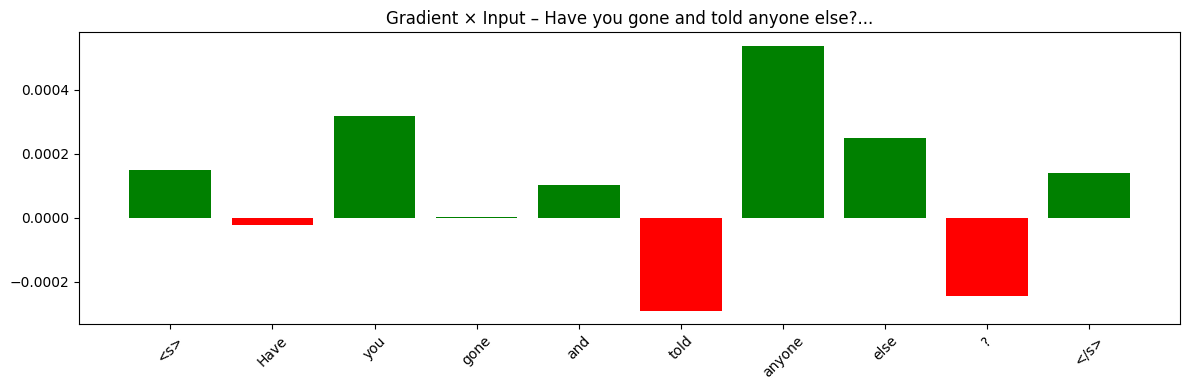


>>> TEXT: Peter not daring to look over.


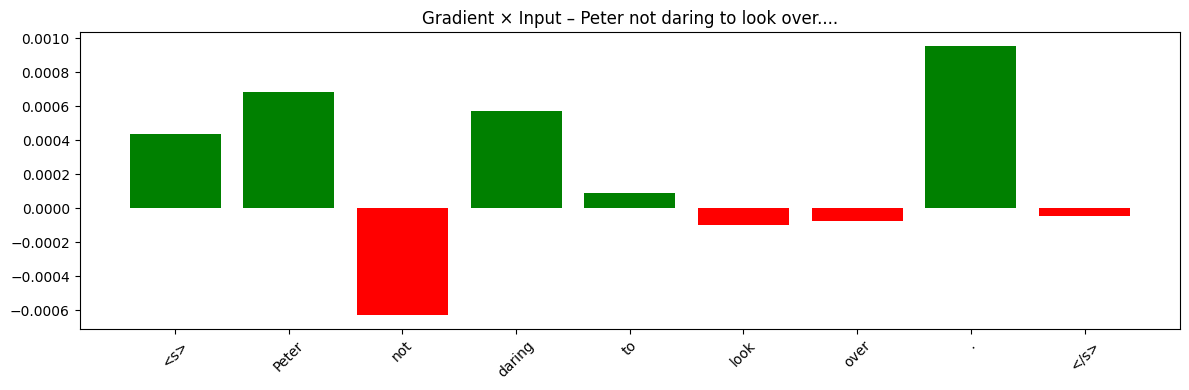


>>> TEXT: But with that necklace I know that I'm safe


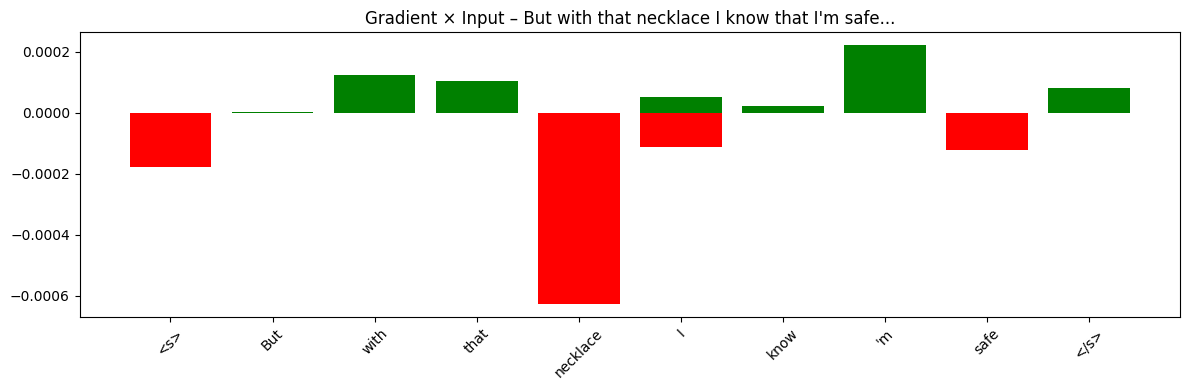


>>> TEXT: The fact that I'm completely safe tonight means if it's a tie Tara Pete and Jericho are gonna have to draw for rocks


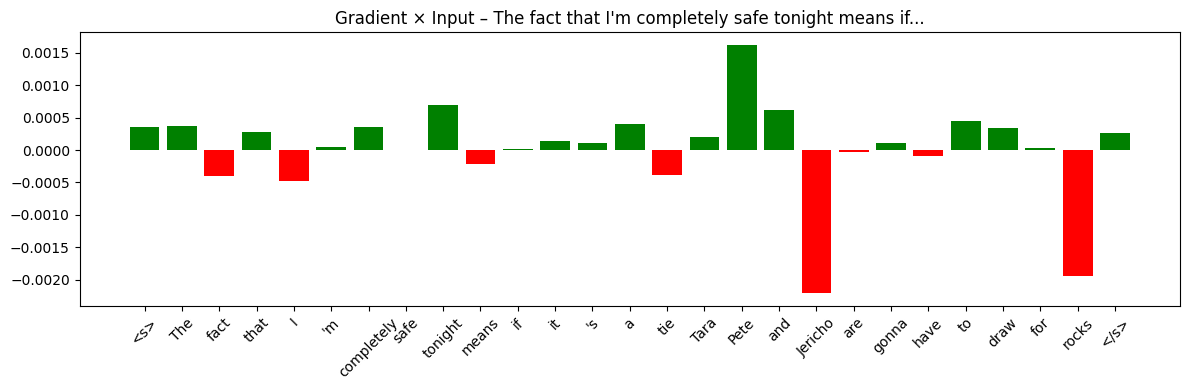


>>> TEXT: So there's a chance that you could go home tonight


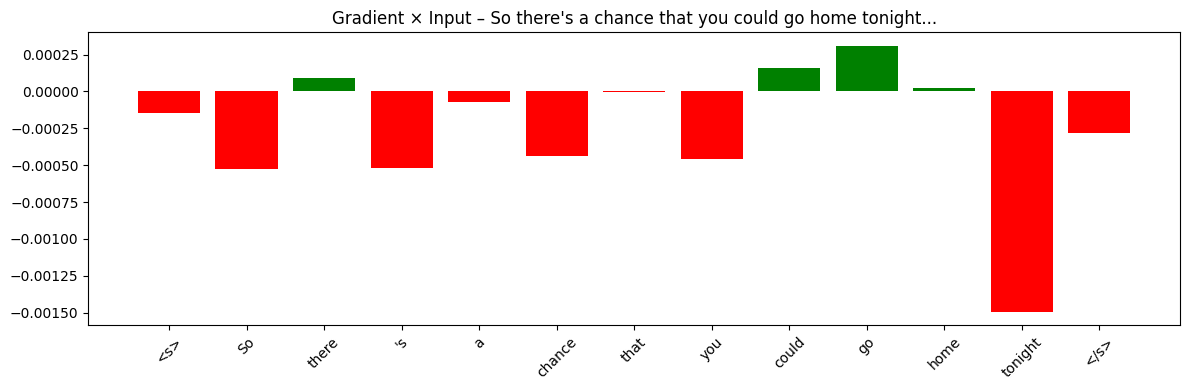


>>> TEXT: I don't even feel bad.


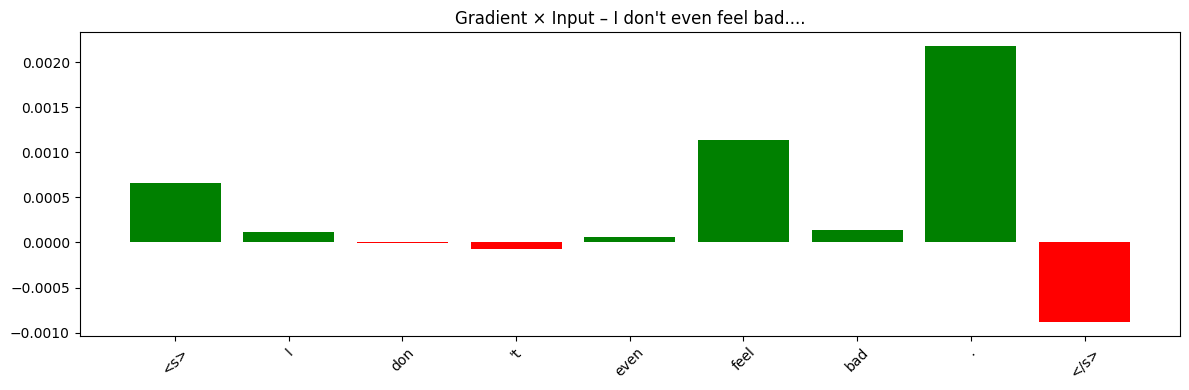


>>> TEXT: With Luke gone, I moved one rung higher.


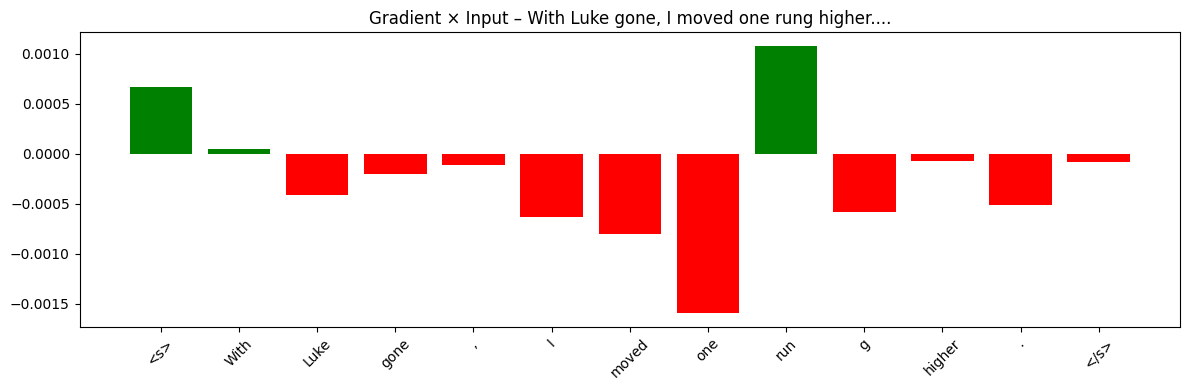


>>> TEXT: You know and I don't want to let the emotions get involved and he won't either


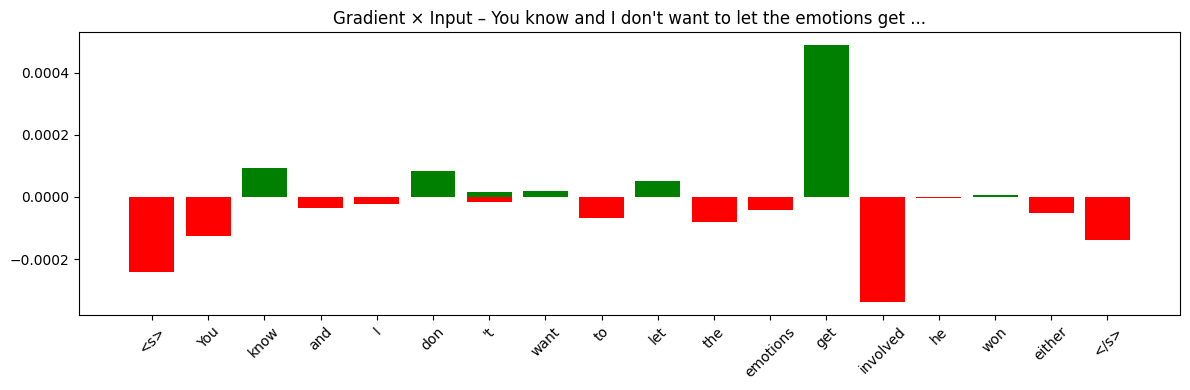


>>> TEXT: I think I definitely am a big target to go home now because it's just easy Jericho.


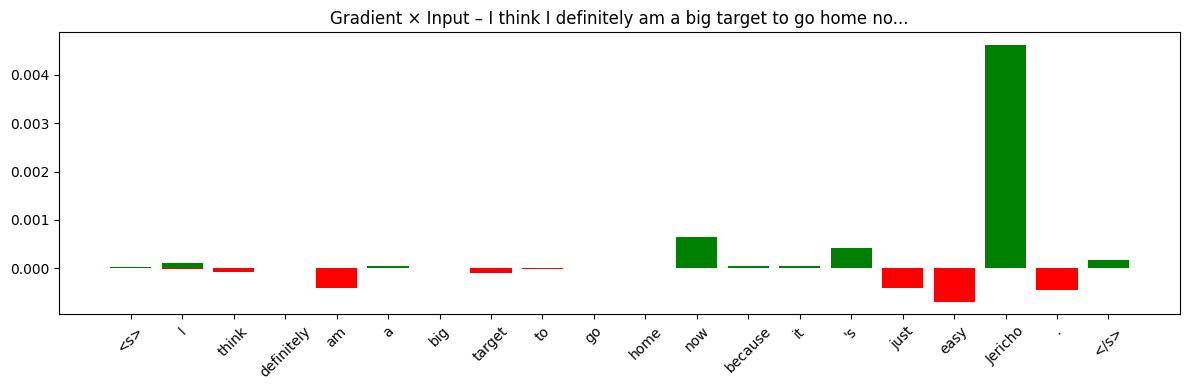


>>> TEXT: I guess Jerry's hurting.


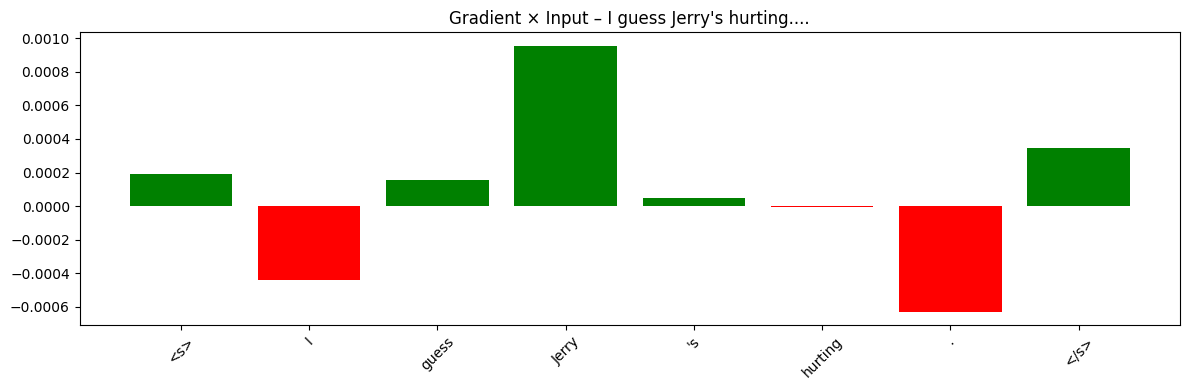


>>> TEXT: but Lachie won the immunity necklace.


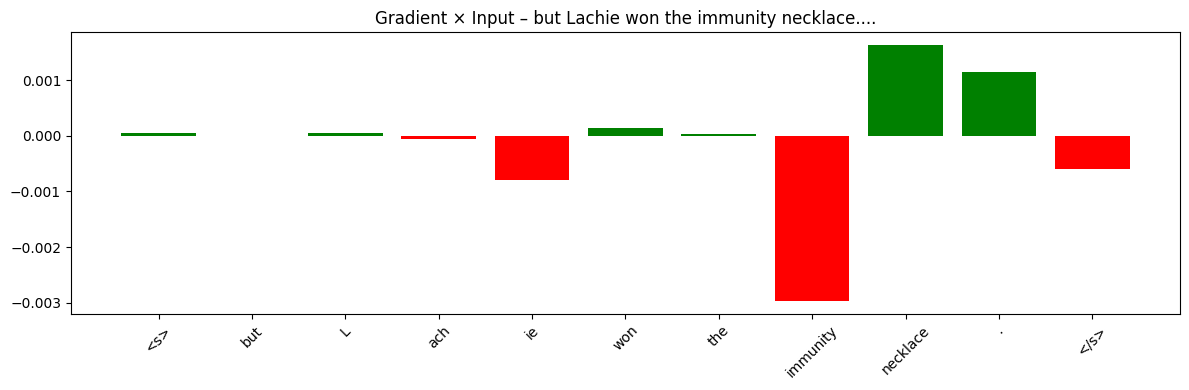


>>> TEXT: It was Tara who spilled the beans to me.


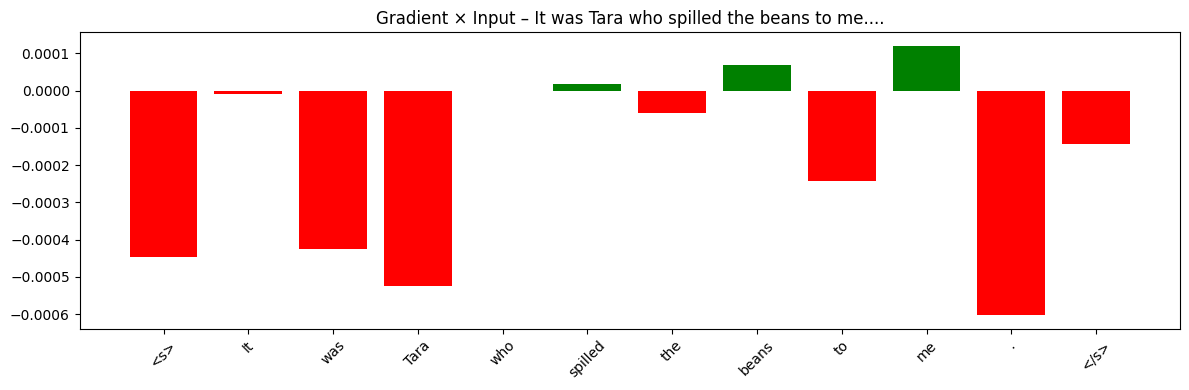


>>> TEXT: And so the other three will then draw rocks


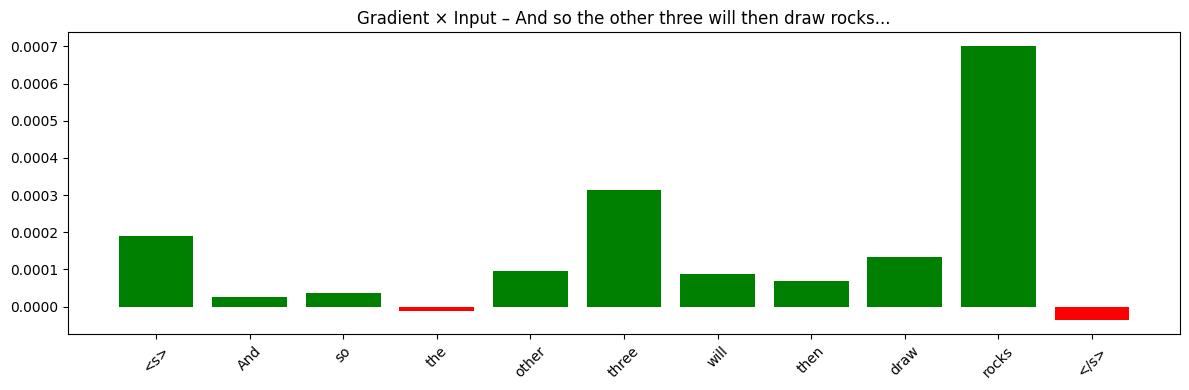


>>> TEXT: Come tribal council, it was between physical threat Ziggy and loose cannon Luke.


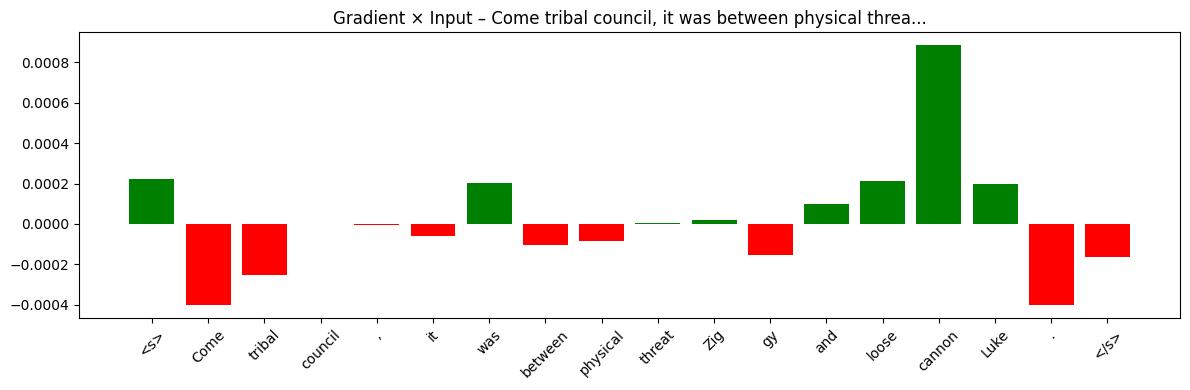

In [7]:
for text in sentences:
    print(f"\n>>> TEXT: {text}")
    
    inputs = tokenizer(text, return_tensors="pt")
    with torch.enable_grad():
        relevance_scores = gradient_x_input(model, inputs)

    tokens = tokenizer.convert_ids_to_tokens(inputs.input_ids[0])
    clean_tokens = [t.replace("Ġ", "") for t in tokens]
    raw_scores = relevance_scores[0].detach().numpy()

    colors = ['red' if score < 0 else 'green' for score in raw_scores[:, 0]]

    plt.figure(figsize=(12, 4))
    plt.bar(clean_tokens, raw_scores[:, 0], color=colors)
    plt.title(f"Gradient × Input – {text[:50]}...", fontsize=12)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Attention Scores

RobertaSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


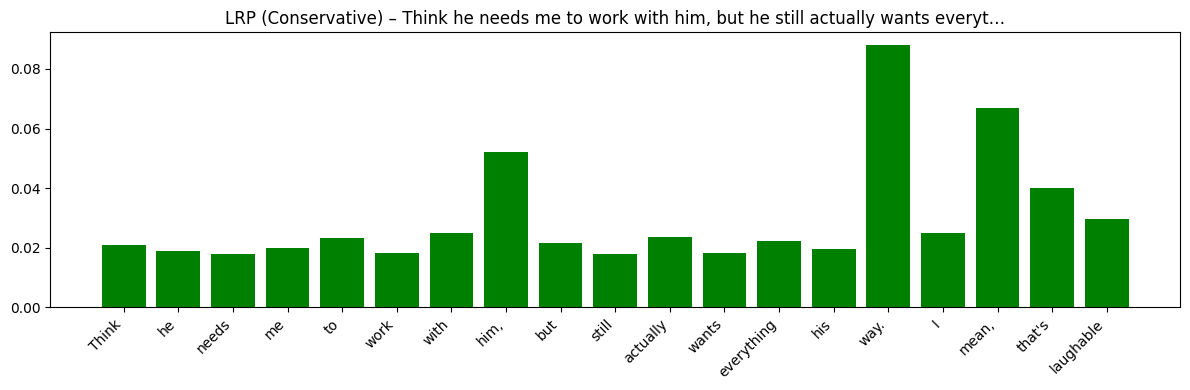

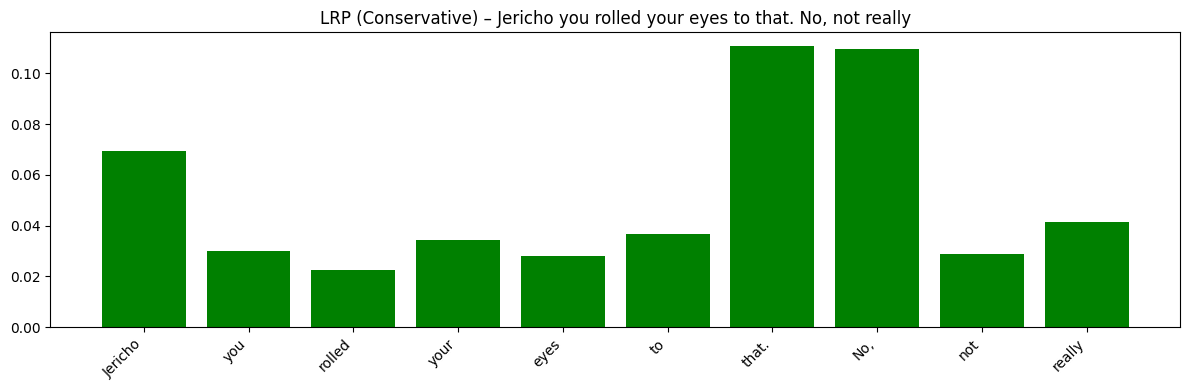

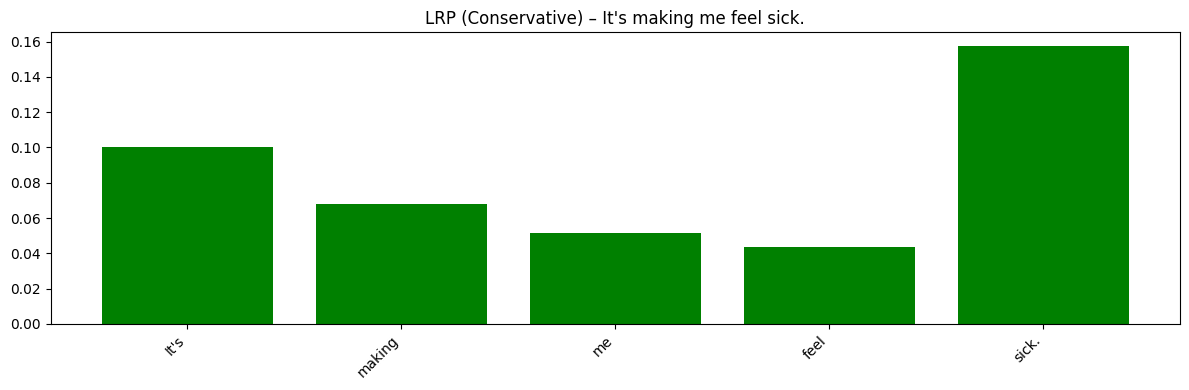

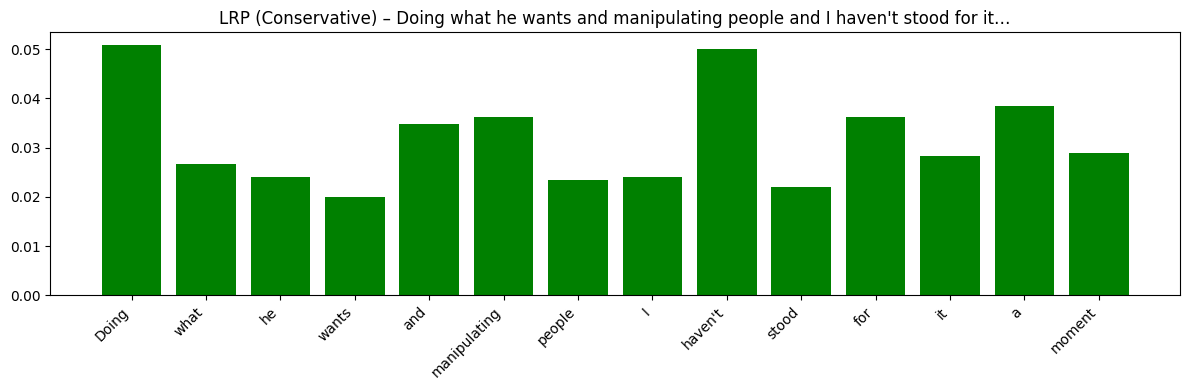

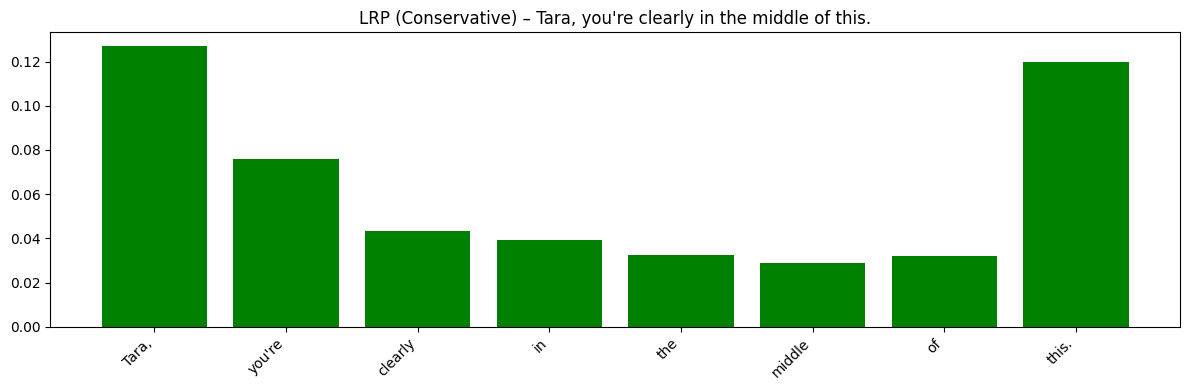

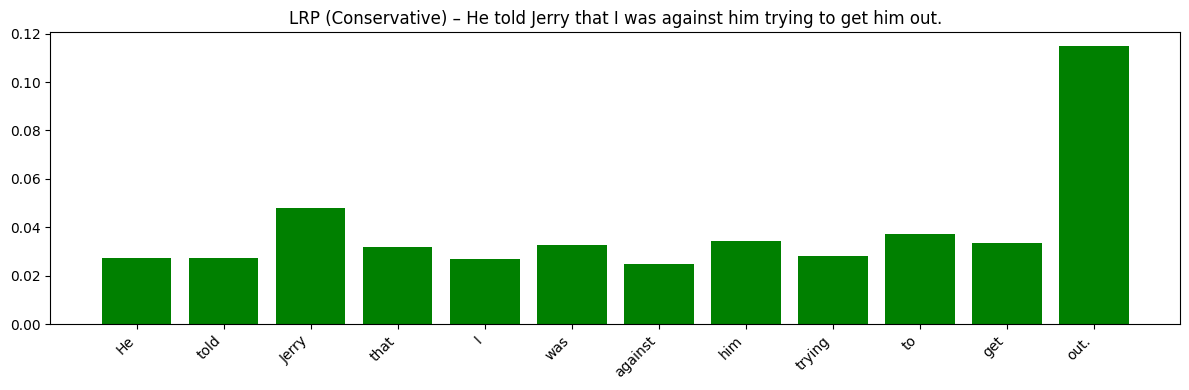

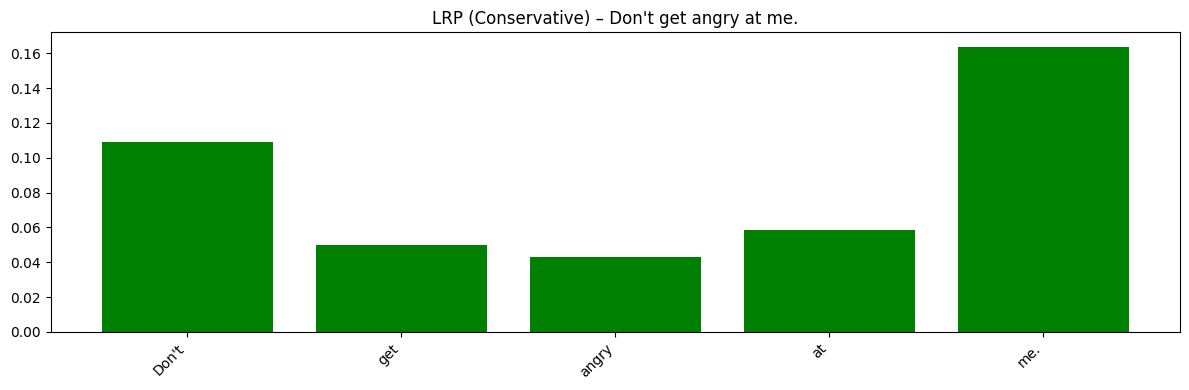

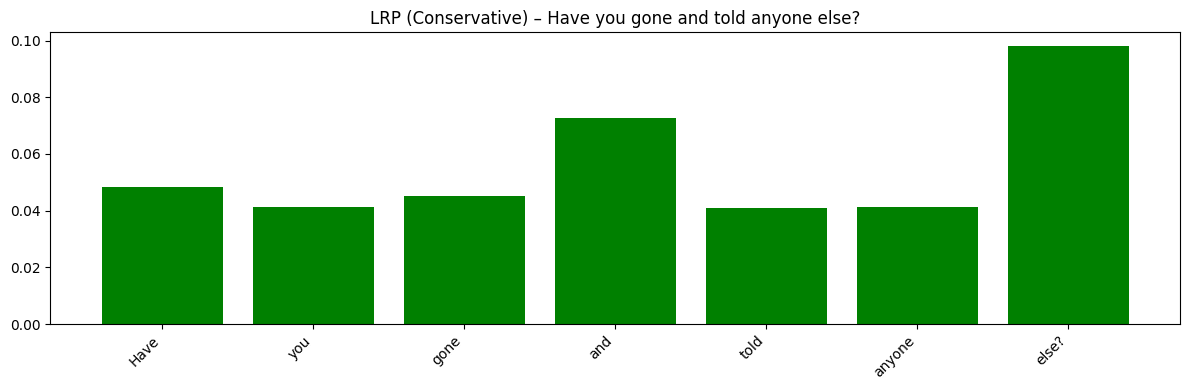

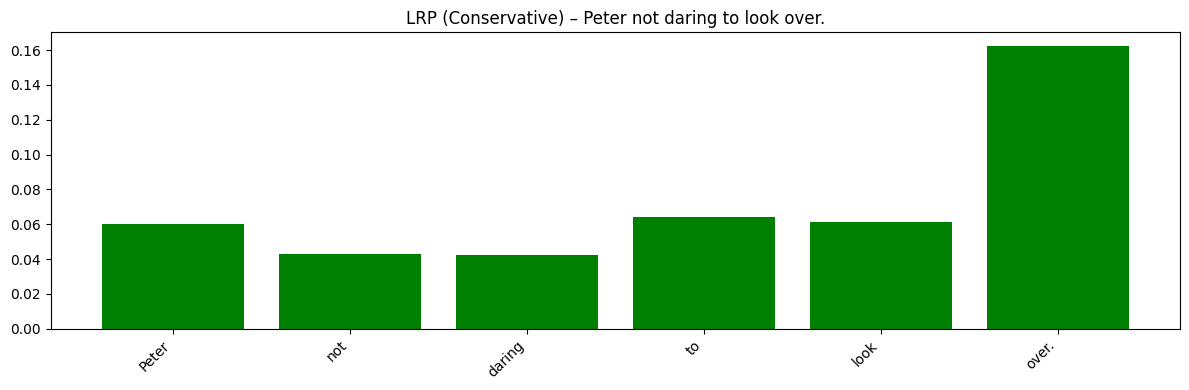

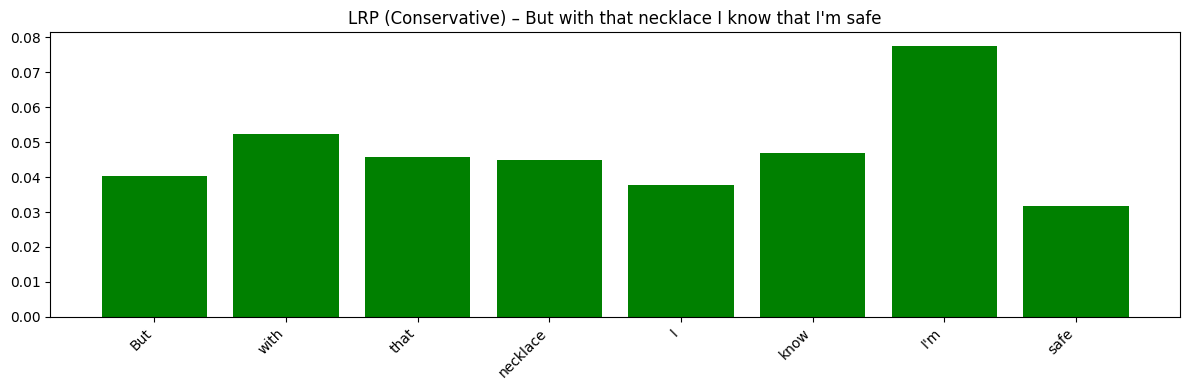

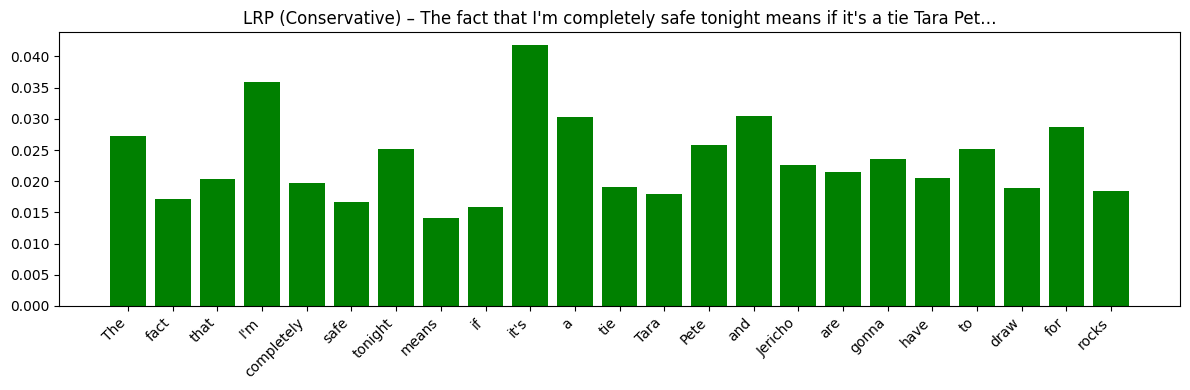

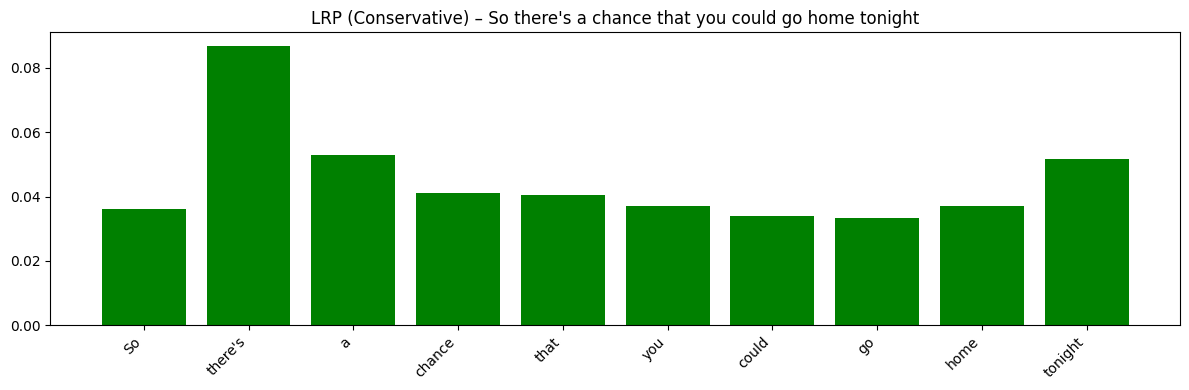

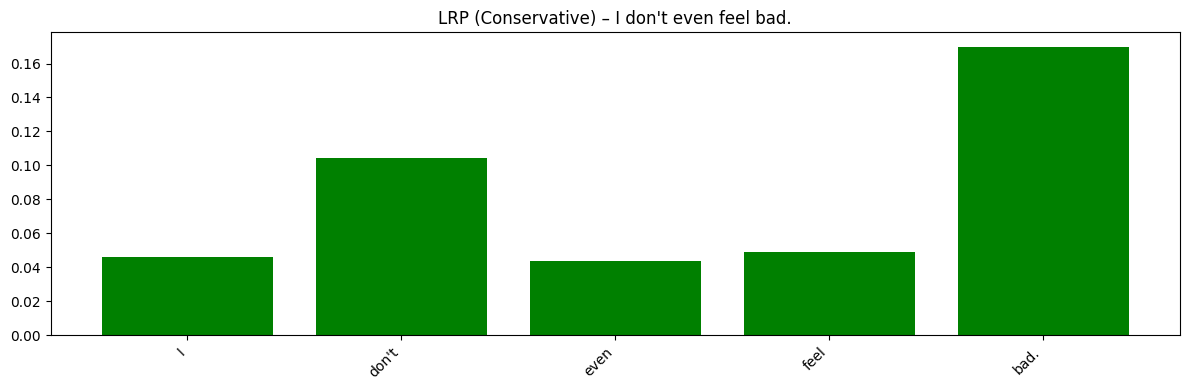

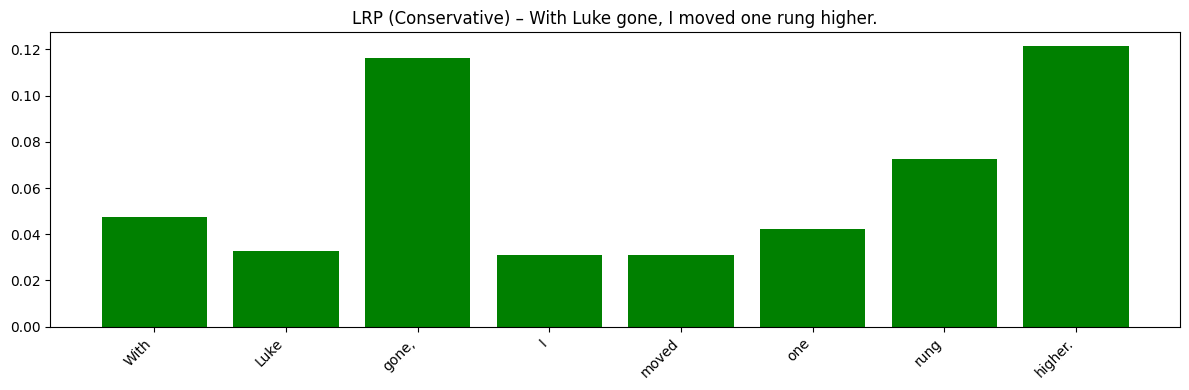

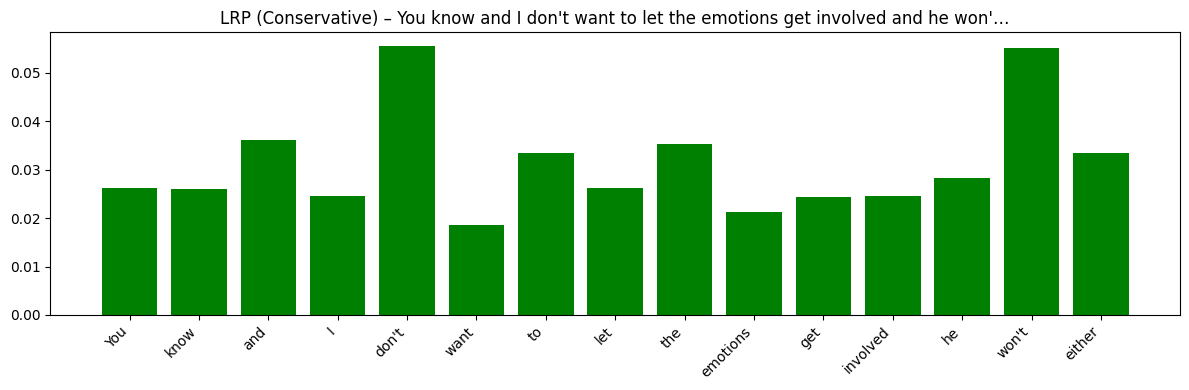

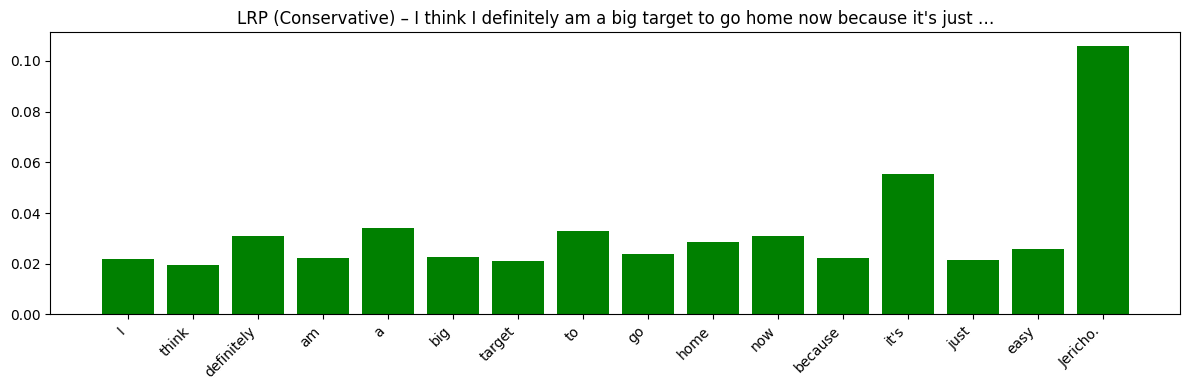

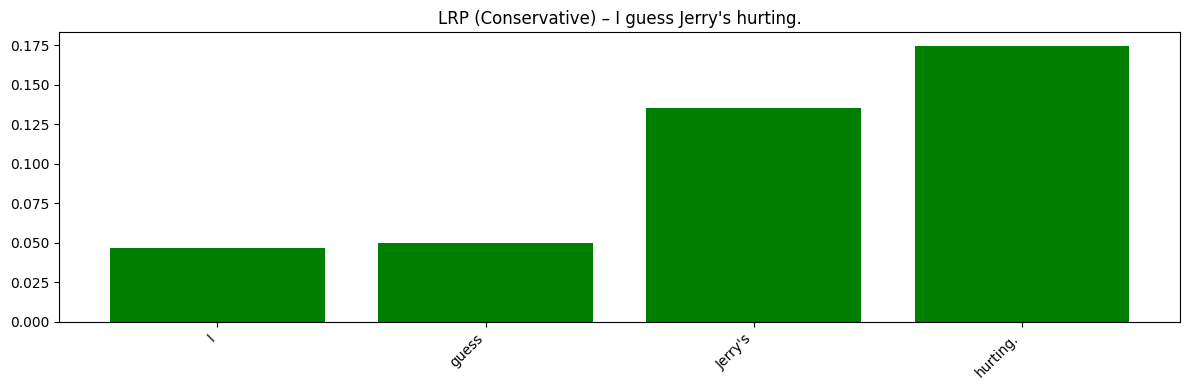

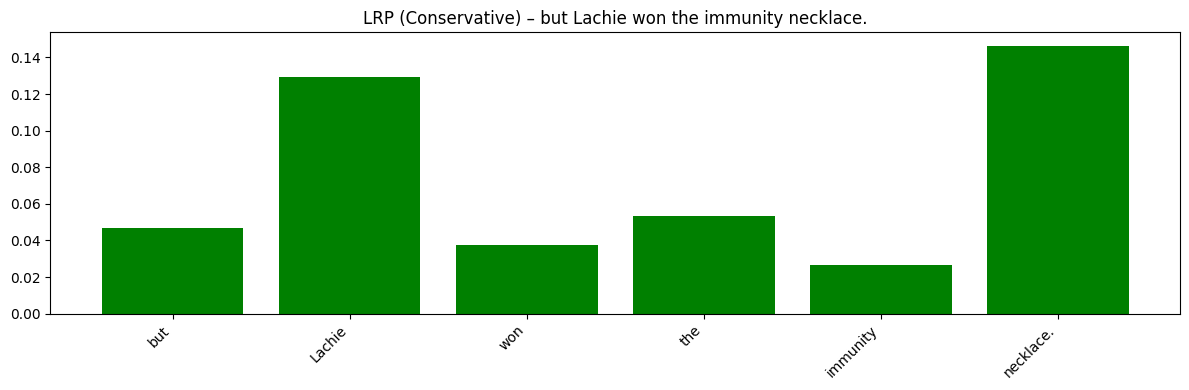

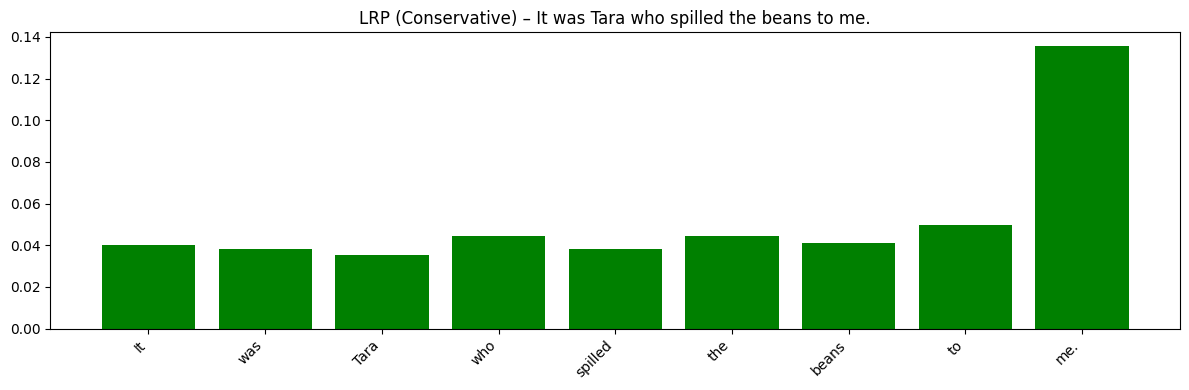

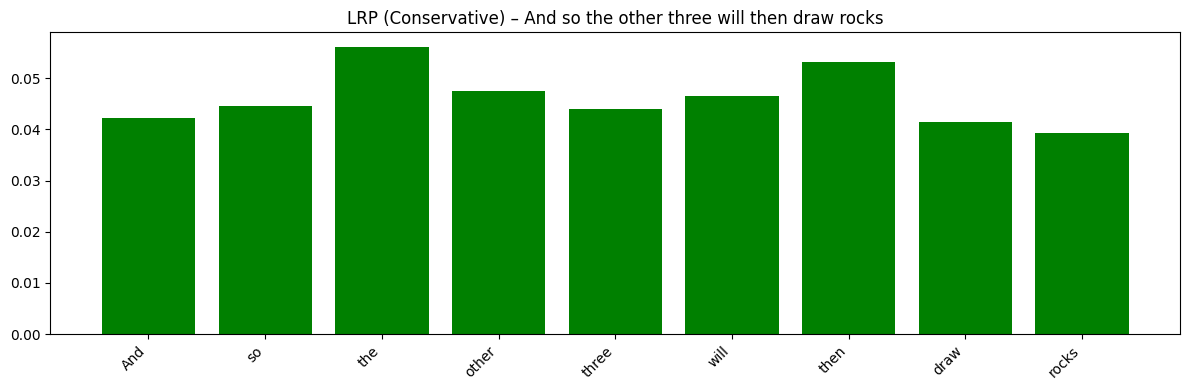

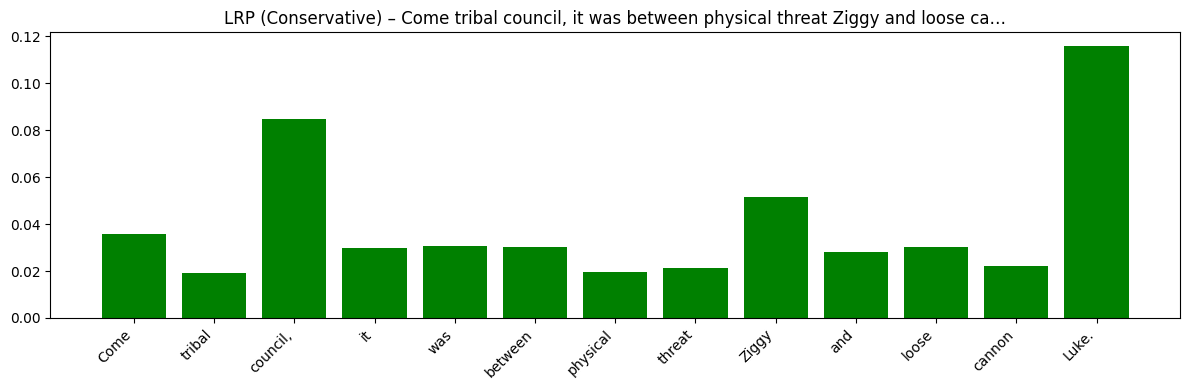

In [8]:
import torch, numpy as np, matplotlib.pyplot as plt, seaborn as sns

# ------- utilities to merge RoBERTa subwords to words -------
def roberta_word_groups(tokens, special_tokens):
    groups, words = [], []
    cur_group, cur_pieces = [], []
    keep_idx = []
    for i, t in enumerate(tokens):
        if t in special_tokens: 
            continue
        start = t.startswith("Ġ")
        piece = t.replace("Ġ","")
        if start:
            if cur_group:
                groups.append(cur_group); words.append("".join(cur_pieces))
            cur_group, cur_pieces = [i], [piece]
        else:
            cur_group.append(i); cur_pieces.append(piece)
        keep_idx.append(i)
    if cur_group: 
        groups.append(cur_group); words.append("".join(cur_pieces))
    return groups, words, keep_idx

def merge_scores_to_words(tokens, scores, tokenizer, agg="sum"):
    groups, words, keep_idx = roberta_word_groups(tokens, set(tokenizer.all_special_tokens))
    if len(groups)==0:
        return [], np.array([])
    # restrict scores to kept tokens
    scores = scores[keep_idx]
    W = len(groups)
    out = np.zeros(W, dtype=np.float32)
    for w, idxs in enumerate(groups):
        idxs_local = [keep_idx.index(i) for i in idxs if i in keep_idx]
        vals = scores[idxs_local]
        out[w] = vals.mean() if agg=="mean" else vals.sum()
    return words, out

# ------- LRP-style conservative propagation -------
@torch.no_grad()
def lrp_conservative_tokens(model, tokenizer, text, target=None, max_length=256):
    """
    Returns: tokens(list[str]), token_relevance (np.array, len=seq_len)
    Method:
      - gets layer attentions & hidden states
      - builds normalized attention with residual (I) -> A_tilde
      - rolls relevance from output to input with conservation
      - multiplies by hidden-state magnitude to bias toward influential representations
    """
    model.eval()
    out = model(
        **tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length),
        output_attentions=True,
        output_hidden_states=True,
    )
    logits = out.logits
    if target is None:
        target = int(logits.argmax(dim=-1))

    # attentions: list[L] of (batch, heads, seq, seq)
    attns = [a[0].cpu().numpy() for a in out.attentions]      # each (H,S,S)
    # hidden states: list[L+1] (emb + L layers)
    hiddens = [h[0].cpu().numpy() for h in out.hidden_states] # shapes (S,d)

    H, S, _ = attns[-1].shape
    # attention rollout with residual (Identity) and head-avg; row-normalize conservatively
    As = []
    for A in attns:
        A = A.mean(0)                       # (S,S)
        A = A + np.eye(S, dtype=np.float32) # add residual
        A = A / (A.sum(axis=-1, keepdims=True) + 1e-12)
        As.append(A)
    # multiply from last to first (attention rollout)
    A_roll = np.eye(S, dtype=np.float32)
    for A in As:
        A_roll = A @ A_roll                 # (S,S)

    # class relevance seed: focus on the <s> (first) token or mean of last layer
    # RoBERTa uses first token as “CLS”-like summary
    cls_idx = 0
    R = np.zeros(S, dtype=np.float32)
    R[cls_idx] = 1.0

    # propagate via rolled attention (conservative: probabilities sum to 1 per row)
    R_tokens = A_roll.T @ R                 # (S,)

    # modulate by representation strength (LayerNorm-like conservative factor)
    rep_power = np.linalg.norm(hiddens[-1], axis=-1)  # last hidden magnitude
    rep_power = rep_power / (rep_power.sum() + 1e-12)
    R_tokens = R_tokens * rep_power
    R_tokens = R_tokens / (np.abs(R_tokens).sum() + 1e-12)

    tokens = tokenizer.convert_ids_to_tokens(
        tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length).input_ids[0]
    )
    return tokens, R_tokens

def plot_lrp_bar(text, tokenizer, model, agg="sum", title_prefix="LRP (Conservative) – "):
    tokens, r_tok = lrp_conservative_tokens(model, tokenizer, text)
    words, r_word = merge_scores_to_words(tokens, r_tok, tokenizer, agg=agg)
    if len(words)==0:
        print("Nothing to plot.")
        return
    colors = ["red" if v<0 else "green" for v in r_word]
    plt.figure(figsize=(12,4))
    plt.bar(words, r_word, color=colors)
    plt.title(f"{title_prefix}{text[:70]}{'…' if len(text)>70 else ''}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


for s in sentences:
    plot_lrp_bar(s, tokenizer, model)


### Model confidence during Token Removal

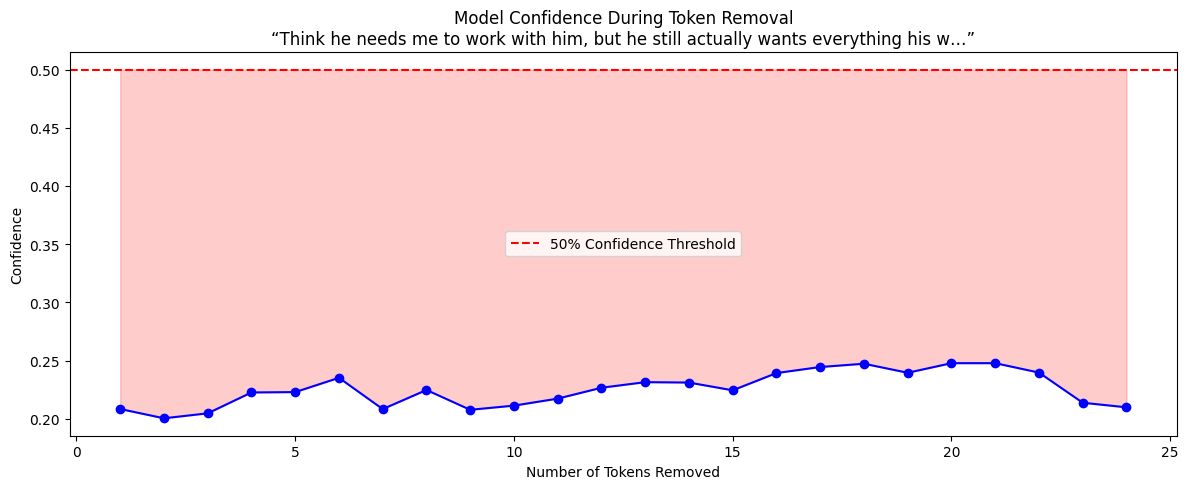

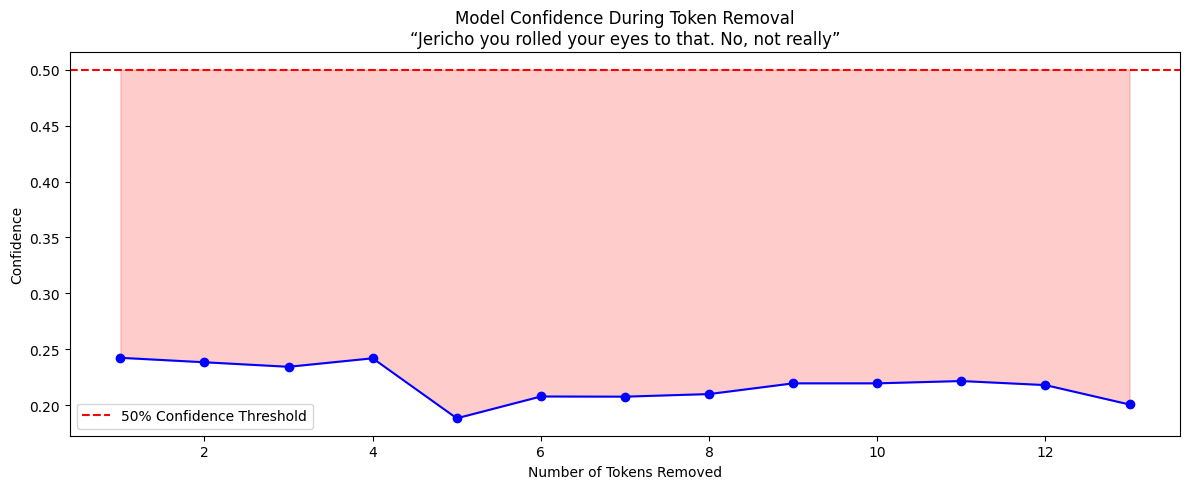

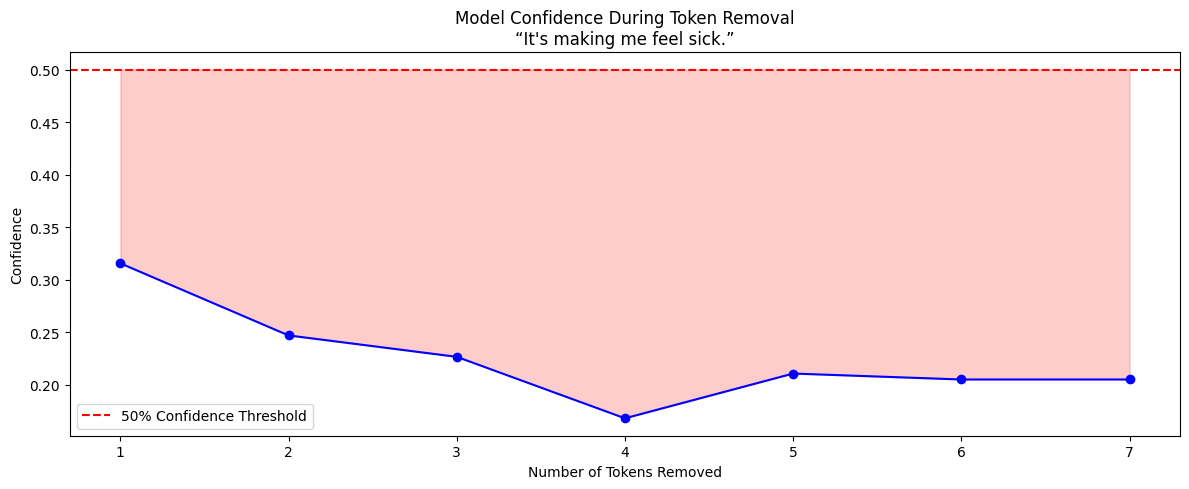

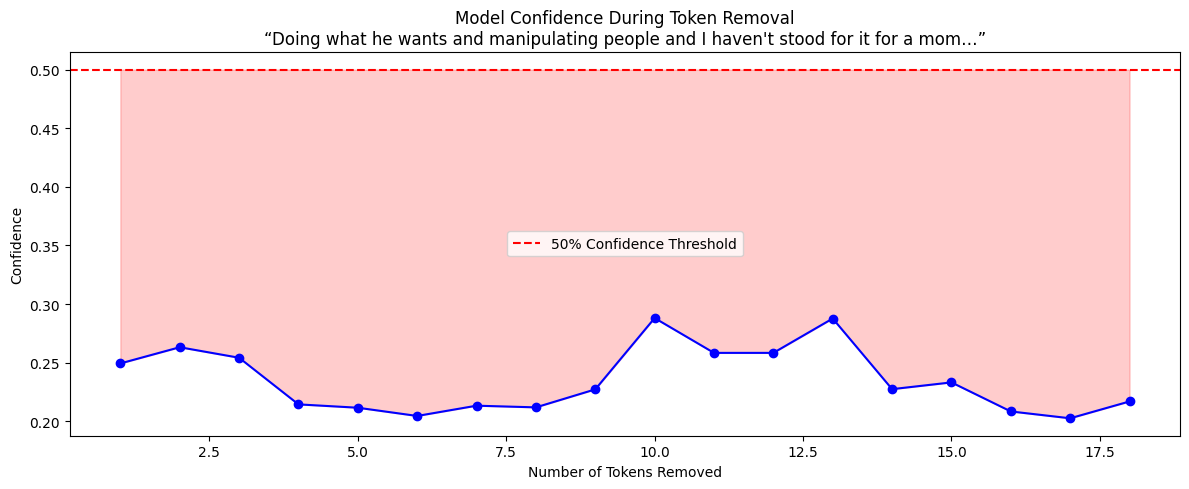

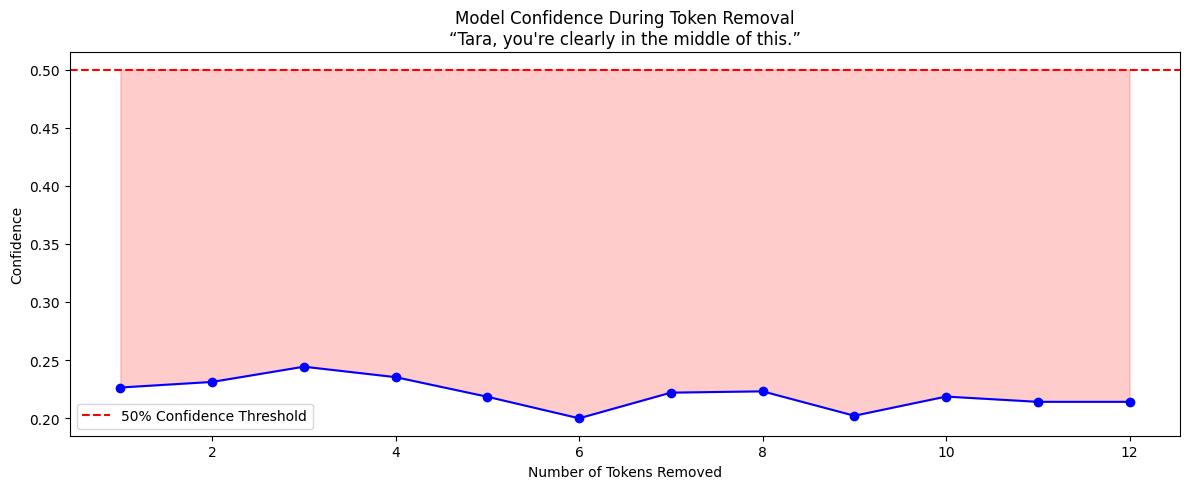

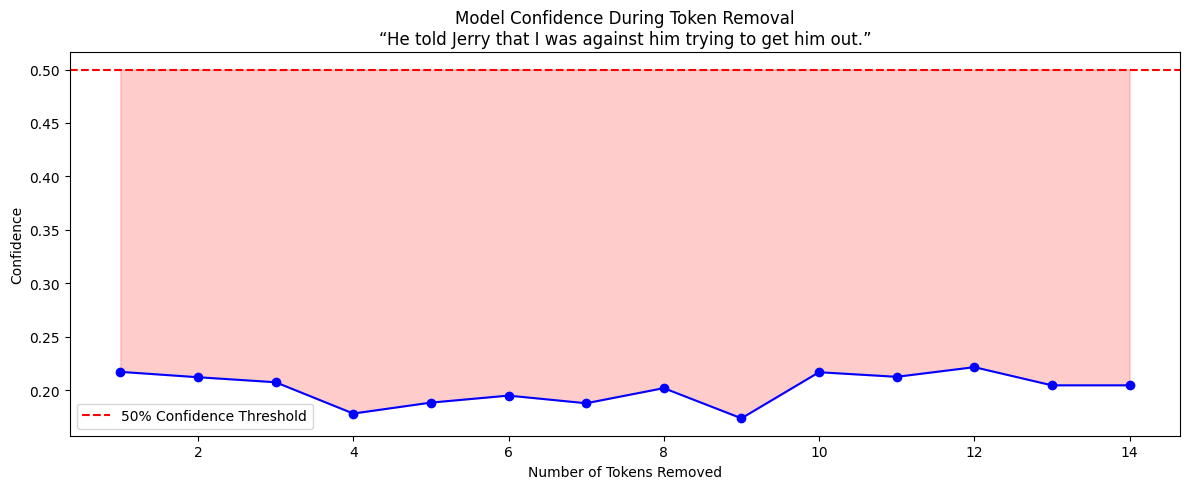

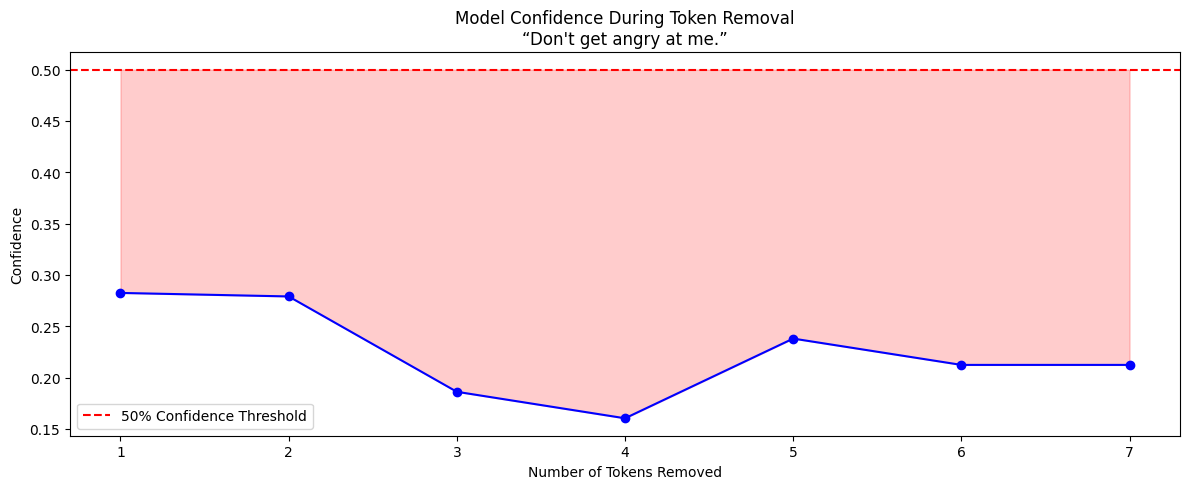

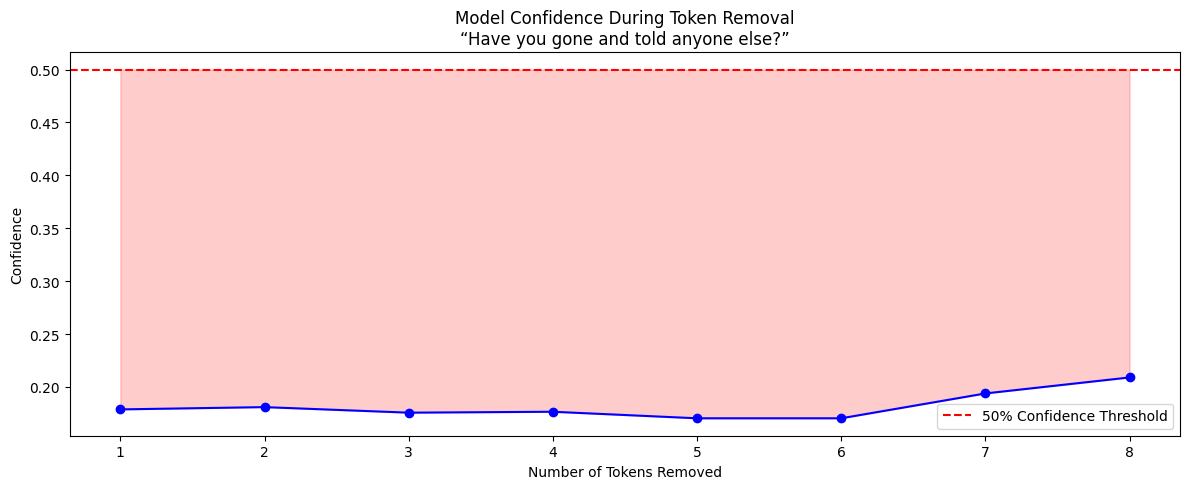

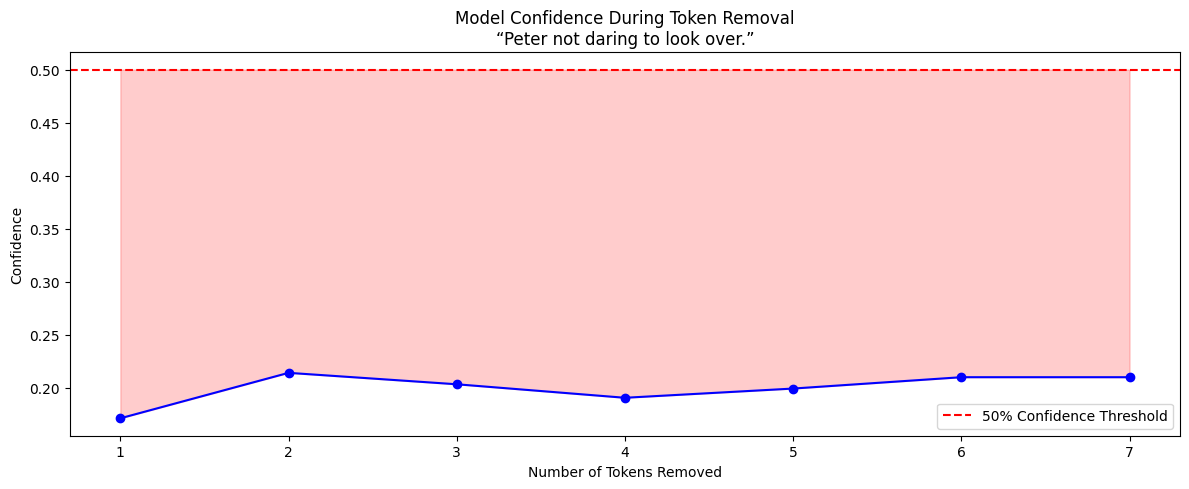

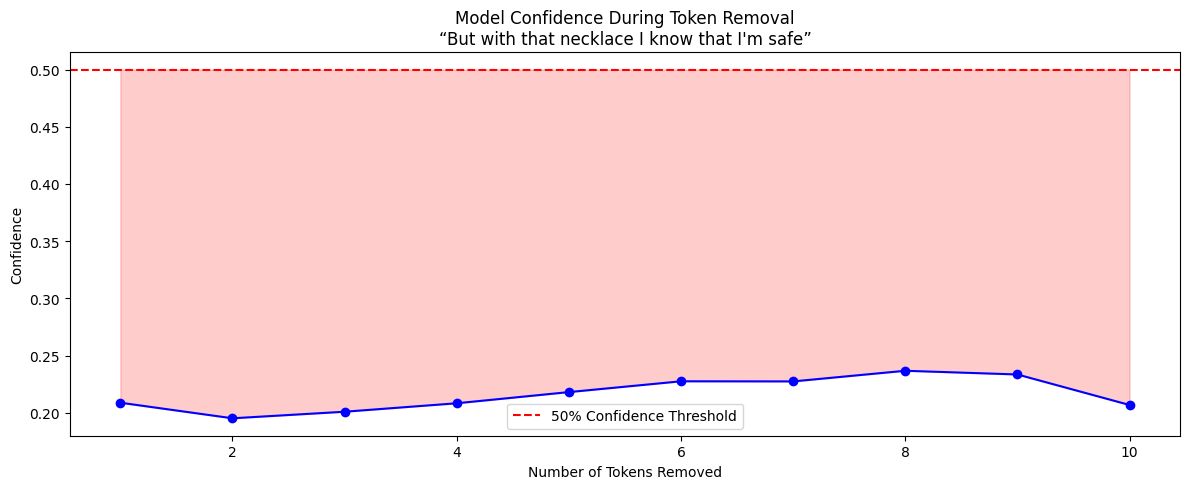

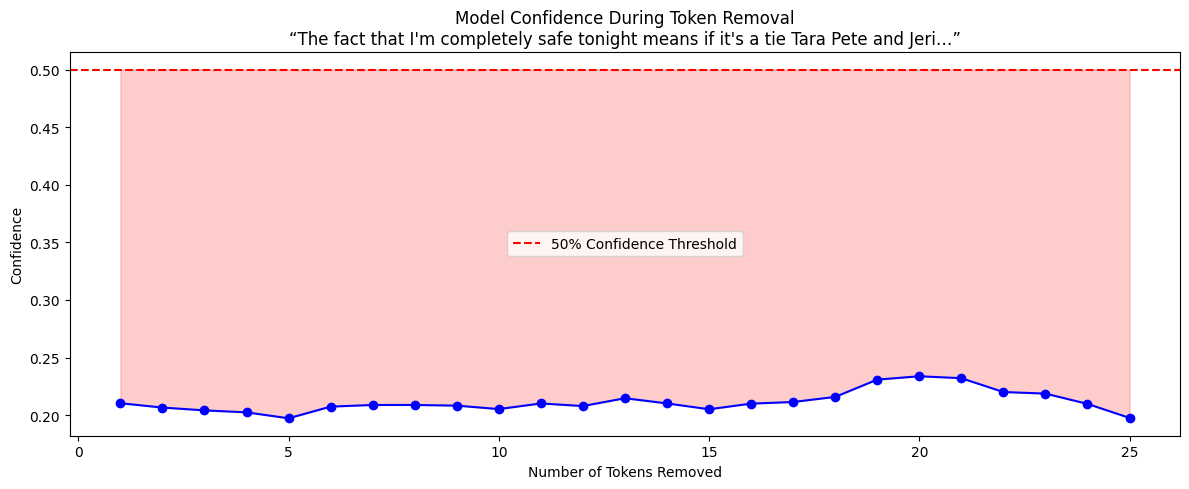

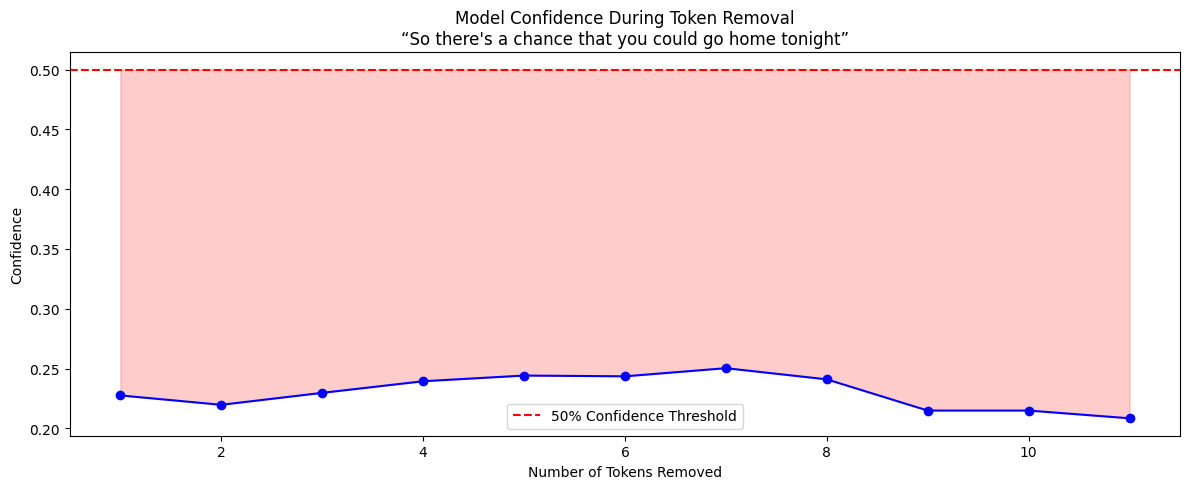

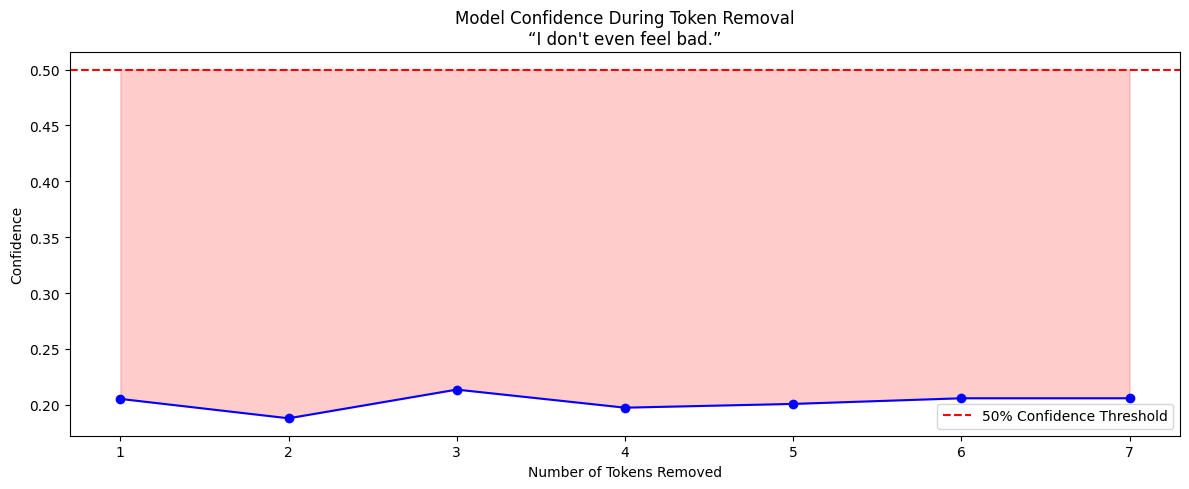

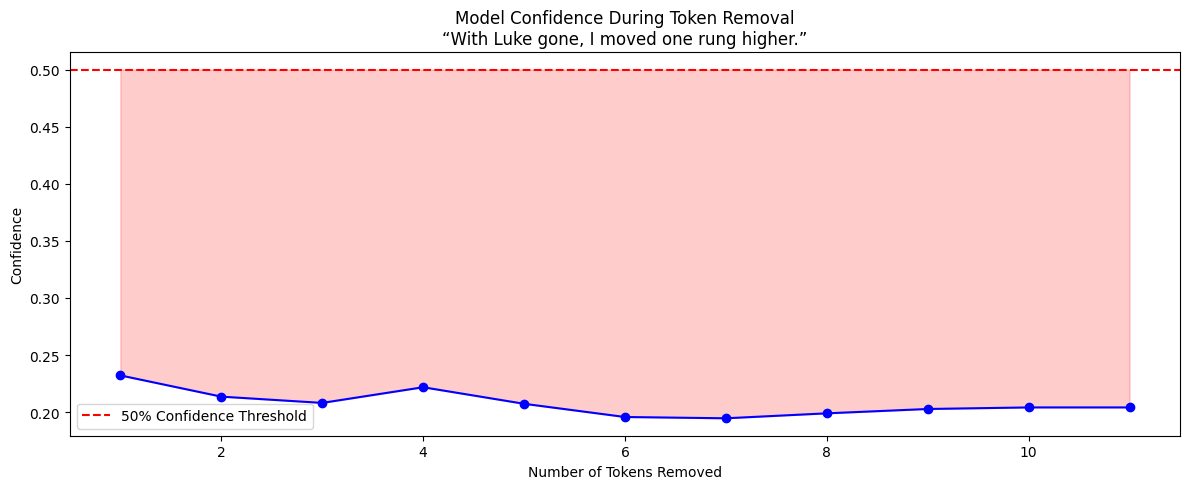

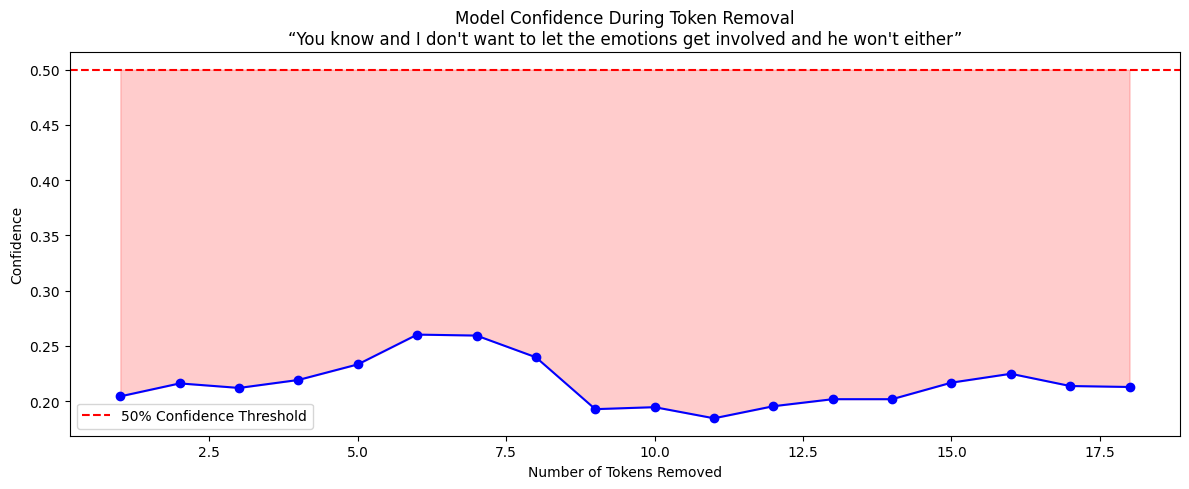

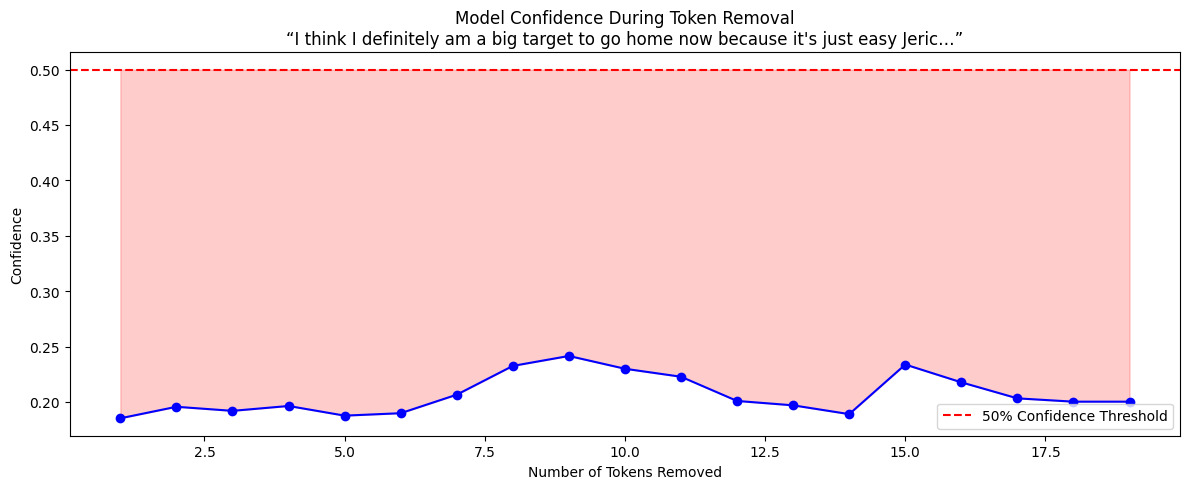

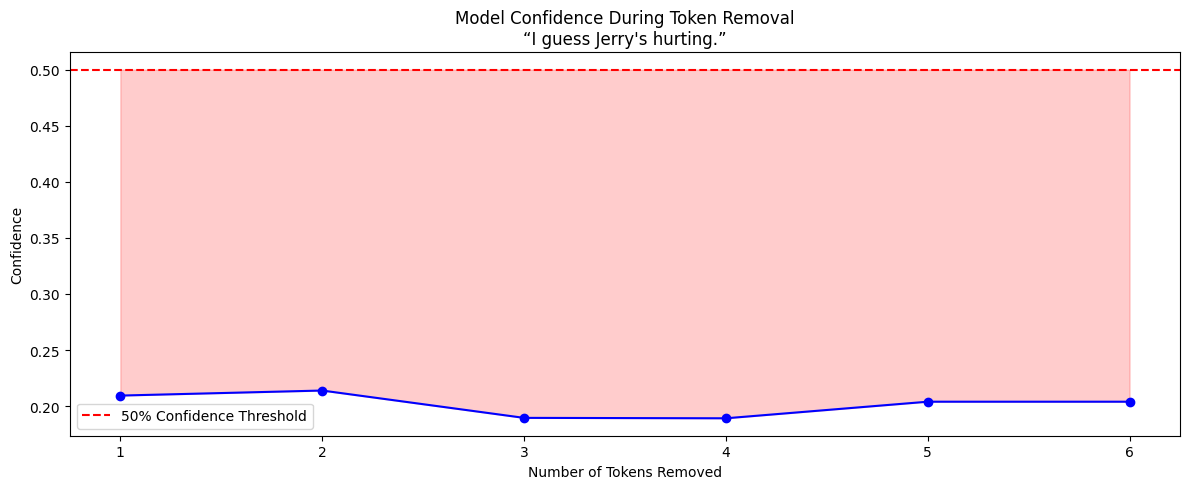

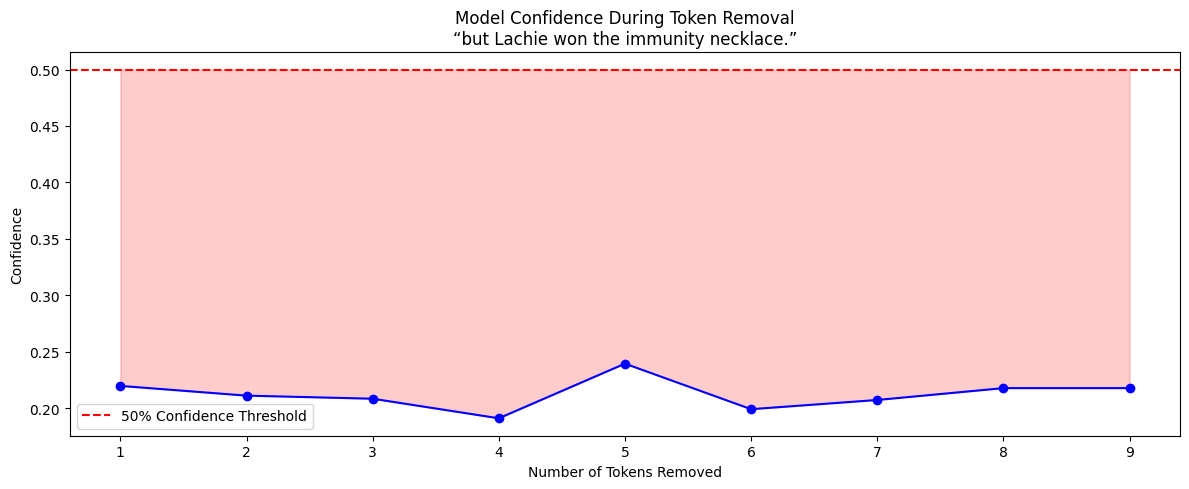

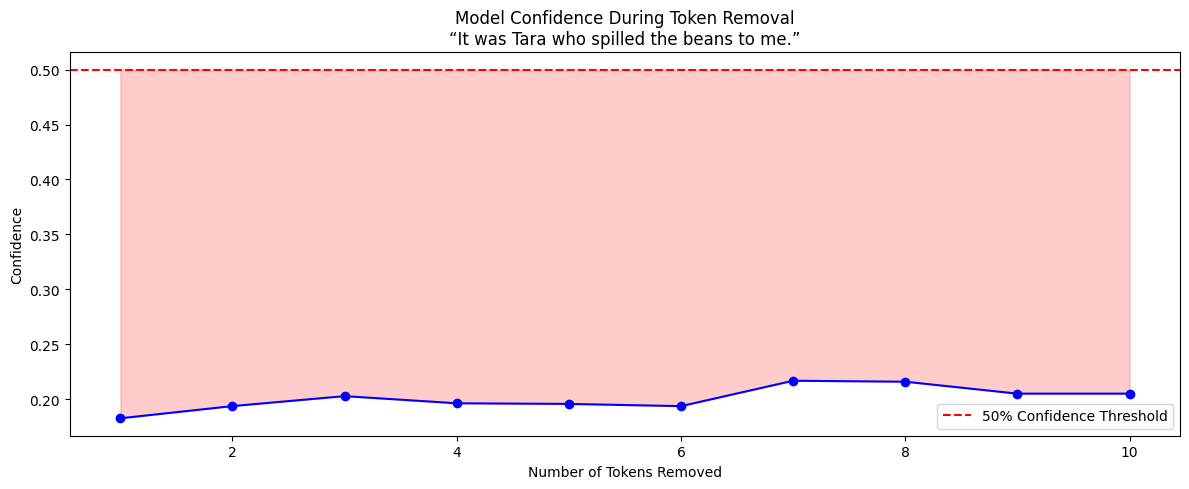

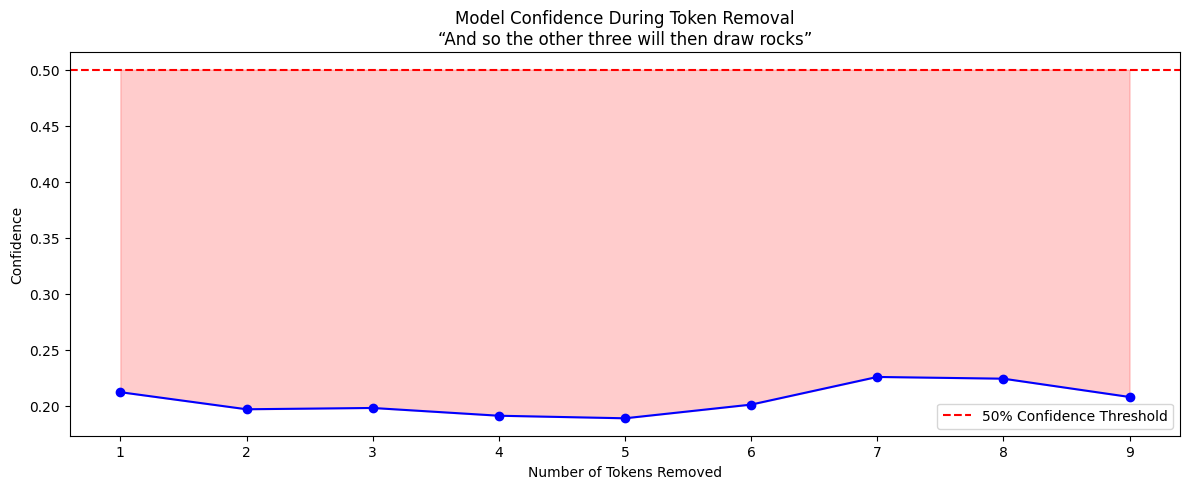

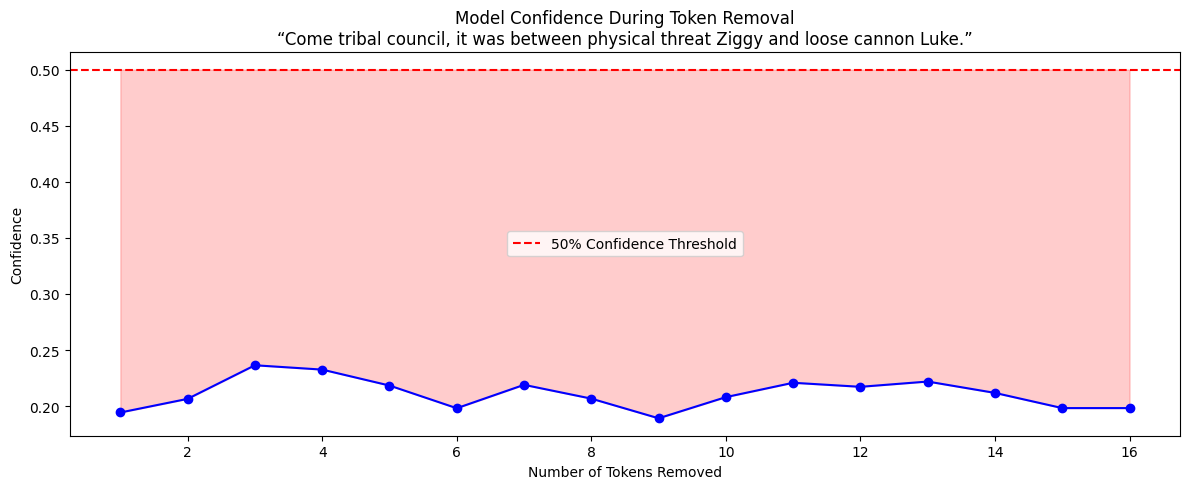

In [12]:
for text in sentences:
    # LRP relevance per token
    lrp_tokens, lrp_scores = lrp_conservative_tokens(model, tokenizer, text) 
    # Tensor with shape (1, seq_len, 1) so the perturb fn works unchanged
    relevance_scores = torch.from_numpy(lrp_scores).float().unsqueeze(0).unsqueeze(-1)

    # Tokens for alignment 
    tokens = tokenizer.tokenize(text)

    # Run existing perturbation function 
    confidences_remove = perturb_input_and_evaluate(
        model, tokenizer, text, relevance_scores, 'remove'
    )

    # 4) Plot
    min_length = min(len(tokens), len(confidences_remove))
    confidences_remove = np.array(confidences_remove)

    plt.figure(figsize=(12, 5))
    plt.plot(range(1, min_length + 1), confidences_remove[:min_length], marker='o', color='blue')
    plt.axhline(y=0.5, color='red', linestyle='--', label="50% Confidence Threshold")
    plt.fill_between(
        range(1, min_length + 1),
        confidences_remove[:min_length],
        0.5,
        where=(confidences_remove[:min_length] < 0.5),
        color='red',
        alpha=0.2
    )
    title_snip = text[:80] + ("…" if len(text) > 80 else "")
    plt.title(f"Model Confidence During Token Removal\n“{title_snip}”")
    plt.xlabel("Number of Tokens Removed")
    plt.ylabel("Confidence")
    plt.legend()
    plt.tight_layout()
    plt.show()